# TMA sonic anemometers versus outside wind: combined report (airflow_report v1)

**Author:** Aaron Roodman (with Claude)
**Date Created:** 2026-11-06
**Last Modified:** 2026-11-06
**Status:** In Progress
**Keywords:** wind, sonic anemometer, ESS airTurbulence, dome, TMA top ring, deployable platform, into-the-wind

## Description
One shareable PDF on how outside wind drives the airflow at the five TMA sonic anemometers:
the four on the top ring (ESS airTurbulence salIndex 123 to 126) and the one on the
deployable-platform railing (salIndex 110). It replaces `wind_vs_sonic_v3` and
`platform_sonic_v1`, with the same plots plus a summary, a definitions page, a geometry
sketch and a caption on every figure. Captions and definitions live in the `CAPS` and
`DEFS` cells so they can be edited without touching the plotting code.

**Output:** `airflow_report.pdf` in the study run directory.
**References:** `value_added/docs/schema.md` (`sonic`, `wind_derived`, `louvers` groups);
`ts_ess_common` `AirTurbulenceAccumulator` (per-row EFD statistics).


## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-06 | Aaron Roodman | Initial version: merges wind_vs_sonic_v3 and platform_sonic_v1, adds explanatory pages and captions |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Analysis](#analysis)
6. [Text: summary, definitions, captions](#text)
7. [Results & Plots](#results)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS_MIN, DAY_OBS_MAX = 20260120, 20260714   # sonic data start 20260120; no observing after 20260714
PLATFORM_MIN = 20260226                # EFD location first reads "TMA deployable platform"
IMG_TYPES = ('science', 'acq', 'cwfs')
SONICS = (123, 124, 125, 126)          # TMA top ring
SONIC_P = 110                          # deployable platform
TOWARD_CUT = -0.3                      # axis-2 mean below this = toward M1M3 [m/s]
WIND_MIN = 6.0                         # high-wind cut [m/s]
WIND_LOW = (1.0, 6.0)                  # low-wind range [m/s]
WIND_QUIVER_LOW = (2.0, 6.0)           # low-wind range for the top-ring flow-vector page [m/s]
ANGLE_STEP = 15                        # into_wind_deg bin width [deg]
ALT_STEP = 5                           # altitude bin width [deg]
U_EDGES = [0, 1.5, 3, 4.5, 6, 7.5, 9, 10.5, 12, 15]   # outside wind bins [m/s]
ALT_SPLIT = 50                         # low/high altitude split [deg]
ALT_BANDS = [(15, 45), (45, 65), (65, 90)]            # altitude bands [deg]
MIN_CELL = 20                          # minimum exposures per bin or cell
NIGHT_MIN = 50                         # minimum exposures for a per-night point
EPOCHS = [(20260226, 20260422), (20260423, 20260511), (20260512, 20260714)]  # platform response steps
LOUVER_STATES = [(-0.5, 0.5, '0 open'), (4.5, 5.5, '5 open'), (5.5, 6.5, '6 open')]

run = study_run('airflow/airflow_correlations', 'airflow_report')
PDF = run.path / 'airflow_report.pdf' 

<a id='setup'></a>
## Setup & Imports

In [2]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from scipy import stats

from rubinwork.products.value_added import reader
from rubinwork.common.telemetry_clients import make_consdb_client
from rubinwork.common.utils import nmad

<a id='functions'></a>
## Helper Functions

In [3]:
def binned_median(x, y, edges, nmin=MIN_CELL):
    """Median and count of y in bins of x; NaN where fewer than nmin."""
    ok = np.isfinite(x) & np.isfinite(y)
    med = stats.binned_statistic(x[ok], y[ok], 'median', bins=edges).statistic
    n = np.histogram(x[ok], edges)[0]
    med[n < nmin] = np.nan
    return 0.5 * (edges[1:] + edges[:-1]), med, n


def map2d(x, y, z, xe, ye, stat='median', nmin=MIN_CELL):
    """2D binned statistic of z, NaN where a cell has fewer than nmin values."""
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    s = stats.binned_statistic_2d(x[ok], y[ok], z[ok], stat, bins=[xe, ye]).statistic
    n = np.histogram2d(x[ok], y[ok], [xe, ye])[0]
    s[n < nmin] = np.nan
    return s.T, n.T


def huber(X, y):
    """Huber RLM of y on the columns of X plus a constant; None if under 30 points."""
    X = np.asarray(X, float)
    X = X[:, None] if X.ndim == 1 else X
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    if ok.sum() < 30:
        return None
    return sm.RLM(y[ok], sm.add_constant(X[ok], has_constant='add'),
                  M=sm.robust.norms.HuberT()).fit()


def four_panel(title):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
    fig.suptitle(title, fontsize=11)
    return fig, axs


def wrap(text, width):
    return '\n'.join(textwrap.fill(p, width) if p.strip() else '' for p in text.split('\n'))


def save(fig, fid):
    """Stamp the figure ID, add its caption below the axes, and write the page."""
    title, cap = CAPS[fid]
    fig.text(0.0, 1.0, f'Fig. {fid}', fontsize=11, weight='bold', va='bottom', ha='left',
             transform=fig.transFigure)
    width = int(15.5 * fig.get_figwidth())
    fig.text(0.02, -0.01, wrap(f'Fig. {fid}. {title}. {cap}', width), fontsize=8.5,
             va='top', ha='left', transform=fig.transFigure)
    pdf.savefig(fig, bbox_inches='tight'); plt.show()


def prose_page(title, body, size=9.5):
    """One page of wrapped prose; lines starting with two spaces are set in monospace (formulas, lists)."""
    fig = plt.figure(figsize=(8.5, 11))
    fig.text(0.06, 0.965, title, fontsize=14, weight='bold', va='top')
    y, dy = 0.93, size * 1.32 / 72 / 11
    for p in body.split('\n'):
        if p.startswith('  '):
            lines, fam = [p], 'monospace'
        else:
            lines, fam = (textwrap.wrap(p, int(7.0 * 72 / (size * 0.5)), subsequent_indent='   ')
                          or ['']), None
        for ln in lines:
            head = ln.startswith('# ')
            fig.text(0.06, y, ln[2:] if head else ln, fontsize=size if fam is None else size - 0.8,
                     family=fam, va='top', weight='bold' if head else 'normal')
            y -= dy
    pdf.savefig(fig); plt.show()


def table_page(title, intro, df):
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.03, 0.96, title, fontsize=12, weight='bold', va='top')
    fig.text(0.03, 0.92, wrap(intro, 170), fontsize=8.5, va='top')
    fig.text(0.03, 0.84, df.to_string(), family='monospace', fontsize=7.5, va='top')
    pdf.savefig(fig); plt.show()

<a id='data'></a>
## Data Access

One query of the value-added per-exposure table, joined with ConsDB for `img_type` and altitude. `d` is the top-ring sample (needs altitude); `p` is the platform sample (from `PLATFORM_MIN`, needs sonic 110).

In [4]:
con = reader.open_db()
cols = ['visit_id', 'day_obs', 'wind_speed_ms', 'wind_dir_deg', 'azimuth_deg',
        'into_wind_deg', 'louvers_n_open']
for i in SONICS + (SONIC_P,):
    cols += [f'sonic{i}_mean_{a}_ms' for a in range(3)]
vt = con.sql(f"select {', '.join(cols)} from visit_telemetry "
             f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").df()
ex = make_consdb_client().query(
    f"select exposure_id as visit_id, img_type, altitude from cdb_lsstcam.exposure "
    f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").to_pandas()
allx = vt.merge(ex, on='visit_id', how='inner')
allx['altitude'] = pd.to_numeric(allx['altitude'], errors='coerce')
allx = allx[allx.img_type.isin(IMG_TYPES) & allx.wind_speed_ms.notna() & allx.into_wind_deg.notna()].copy()
th, U = np.radians(allx.into_wind_deg), allx.wind_speed_ms
allx['louver_state'] = None
for lo, hi, lab in LOUVER_STATES:
    allx.loc[(allx.louvers_n_open > lo) & (allx.louvers_n_open <= hi), 'louver_state'] = lab

# Top ring
d = allx[allx.altitude.notna()].copy()
th, alt, U = np.radians(d.into_wind_deg), np.radians(d.altitude), d.wind_speed_ms
d['u_par'] = U * np.cos(th)
d['u_ax'] = -U * np.cos(th) * np.cos(alt)
d['u_el'] = U * np.cos(th) * np.sin(alt)
d['u_az'] = -U * np.sin(th)
for i in SONICS:
    d[f'sonic{i}_perp_ms'] = np.hypot(d[f'sonic{i}_mean_0_ms'], d[f'sonic{i}_mean_1_ms'])
d['ax2_avg_ms'] = d[[f'sonic{i}_mean_2_ms' for i in SONICS]].mean(axis=1, skipna=False)
d['perp_avg_ms'] = d[[f'sonic{i}_perp_ms' for i in SONICS]].mean(axis=1, skipna=False)
w = d[d.wind_speed_ms >= WIND_MIN]
wlow = d[(d.wind_speed_ms >= WIND_LOW[0]) & (d.wind_speed_ms < WIND_LOW[1])]

# Platform
s = f'sonic{SONIC_P}'
p = allx[(allx.day_obs >= PLATFORM_MIN) & allx[f'{s}_mean_2_ms'].notna()].copy()
th, U = np.radians(p.into_wind_deg), p.wind_speed_ms
p['u_fwd'] = U * np.cos(th)
p['u_side'] = U * np.sin(th)
p['vec_ms'] = np.sqrt(sum(p[f'{s}_mean_{a}_ms'] ** 2 for a in range(3)))
p['ring_vec_ms'] = np.mean([np.sqrt(sum(p[f'sonic{i}_mean_{a}_ms'] ** 2 for a in range(3)))
                            for i in SONICS], axis=0)
p['epoch'] = None
for lo, hi in EPOCHS:
    p.loc[p.day_obs.between(lo, hi), 'epoch'] = f'{lo}-{hi}'
pw = p[p.wind_speed_ms >= WIND_MIN]
pl = p[(p.wind_speed_ms >= WIND_LOW[0]) & (p.wind_speed_ms < WIND_LOW[1])]
last = p[p.epoch == f'{EPOCHS[-1][0]}-{EPOCHS[-1][1]}']

print(f'top ring: {len(d)} on-sky exposures, {d.day_obs.nunique()} nights, {d.day_obs.min()} to '
      f'{d.day_obs.max()}; {len(w)} with U >= {WIND_MIN} m/s on {w.day_obs.nunique()} nights')
print(f'platform: {len(p)} exposures, {p.day_obs.nunique()} nights; by epoch',
      p.epoch.value_counts().sort_index().to_dict())
print('louver states (top-ring sample):', d.louver_state.value_counts(dropna=False).to_dict())

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


top ring: 70454 on-sky exposures, 111 nights, 20260127 to 20260714; 25741 with U >= 6.0 m/s on 82 nights
platform: 65788 exposures, 101 nights; by epoch {'20260226-20260422': 31251, '20260423-20260511': 6773, '20260512-20260714': 27764}
louver states (top-ring sample): {'6 open': 66800, '5 open': 1944, '0 open': 1536, None: 174}


<a id='analysis'></a>
## Analysis

Top ring: per-sonic summary at U ≥ `WIND_MIN`, slopes on each side of u_ax = 0, per-night averages and the 3x3 coefficients on (u_ax, u_el, u_az). Platform: per-axis Huber fit on (u_fwd, u_side) by epoch, and nightly means.

In [5]:
rows = []
for i in SONICS:
    y = w[f'sonic{i}_mean_2_ms'].to_numpy()
    r = dict(sonic=i, n=int(np.isfinite(y).sum()),
             frac_toward=np.mean(y[np.isfinite(y)] < TOWARD_CUT))
    for xn in ('u_ax', 'u_par'):
        x = w[xn].to_numpy(); ok = np.isfinite(x) & np.isfinite(y)
        f = huber(x, y)
        r[f'slope_{xn}'] = f.params[1]; r[f'err_{xn}'] = f.bse[1]
        r[f'r_{xn}'] = stats.pearsonr(x[ok], y[ok])[0]
        r[f'rho_{xn}'] = stats.spearmanr(x[ok], y[ok])[0]
    rows.append(r)
summary = pd.DataFrame(rows).set_index('sonic')
display(summary.round(3))

arows = []
for i in SONICS:
    for lo, hi in [(15, 90)] + ALT_BANDS:
        s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
        for sgn, lab in ((1, 'u_ax>0'), (-1, 'u_ax<0')):
            t = s_[sgn * s_.u_ax > 0]
            f = huber(t.u_ax.to_numpy(), t[f'sonic{i}_mean_2_ms'].to_numpy())
            if f is None:
                continue
            arows.append(dict(sonic=i, alt_deg=f'{lo}-{hi}', half=lab, n=int(f.nobs),
                              intercept_ms=f.params[0], slope=f.params[1], slope_err=f.bse[1]))
asym = pd.DataFrame(arows)
display(asym.pivot_table(index=['sonic', 'alt_deg'], columns='half', values='slope').round(3))

q25, q75 = (lambda x: x.quantile(0.25)), (lambda x: x.quantile(0.75))
nights = (d.dropna(subset=['ax2_avg_ms', 'perp_avg_ms']).groupby('day_obs')
          .agg(n=('visit_id', 'size'), louvers=('louvers_n_open', 'median'),
               U_mean=('wind_speed_ms', 'mean'), U_q25=('wind_speed_ms', q25), U_q75=('wind_speed_ms', q75),
               ax2_mean=('ax2_avg_ms', 'mean'), ax2_q25=('ax2_avg_ms', q25), ax2_q75=('ax2_avg_ms', q75),
               perp_mean=('perp_avg_ms', 'mean'), perp_q25=('perp_avg_ms', q25), perp_q75=('perp_avg_ms', q75))
          .reset_index())
nights = nights[nights.n >= NIGHT_MIN]

crows = []
for i in SONICS:
    for a in range(3):
        f = huber(d[['u_ax', 'u_el', 'u_az']].to_numpy(), d[f'sonic{i}_mean_{a}_ms'].to_numpy())
        crows.append(dict(sonic=i, axis=a, n=int(f.nobs), const_ms=f.params[0],
                          **{f'c_{k}': f.params[j + 1] for j, k in enumerate(('ax', 'el', 'az'))},
                          **{f'e_{k}': f.bse[j + 1] for j, k in enumerate(('ax', 'el', 'az'))},
                          resid_nmad_ms=nmad(f.resid)))
coef = pd.DataFrame(crows).set_index(['sonic', 'axis'])
display(coef.round(3))

prows = []
for ep, g in [('all', p)] + list(p.groupby('epoch')):
    for a in list(range(3)) + ['vec']:
        y = (g[f'{s}_mean_{a}_ms'] if a != 'vec' else g.vec_ms).to_numpy()
        r = huber(g[['u_fwd', 'u_side']].to_numpy(), y)
        if r is None:
            continue
        prows.append(dict(epoch=ep, axis=a, n=int(r.nobs), const_ms=r.params[0],
                          c_fwd=r.params[1], e_fwd=r.bse[1], c_side=r.params[2], e_side=r.bse[2],
                          resid_nmad_ms=nmad(r.resid),
                          r_U=stats.pearsonr(g.wind_speed_ms, y)[0],
                          rho_U=stats.spearmanr(g.wind_speed_ms, y)[0]))
pcoef = pd.DataFrame(prows).set_index(['epoch', 'axis'])
display(pcoef.round(3))

nt = p.groupby('day_obs').agg(n=('vec_ms', 'size'), U=('wind_speed_ms', 'mean'),
                              vec=('vec_ms', 'mean'), ring=('ring_vec_ms', 'mean'),
                              **{f'ax{a}': (f'{s}_mean_{a}_ms', 'mean') for a in range(3)})
nt = nt[nt.n >= NIGHT_MIN]
nt['date'] = pd.to_datetime(nt.index.astype(str))
for ep, g in p.groupby('epoch'):
    print(ep, f'median vec / U = {(g.vec_ms / g.wind_speed_ms.clip(lower=0.5)).median():.2f} '
          '(dimensionless)')

,n,frac_toward,slope_u_ax,err_u_ax,r_u_ax,rho_u_ax,slope_u_par,err_u_par,r_u_par,rho_u_par
sonic,,,,,,,,,,
123,25741,0.030,-0.062,0.001,-0.295,-0.393,0.034,0.000,0.319,0.426
124,25740,0.111,0.010,0.001,0.139,0.053,-0.002,0.000,-0.103,0.003
125,25740,0.230,0.127,0.001,0.571,0.530,-0.058,0.001,-0.537,-0.522
126,25741,0.069,-0.010,0.001,0.064,-0.060,0.006,0.000,-0.063,0.043


half           u_ax<0  u_ax>0
sonic alt_deg                
123   15-45    -0.058   0.009
      15-90    -0.121  -0.017
      45-65    -0.122  -0.025
      65-90    -0.229  -0.053
124   15-45     0.036   0.011
      15-90     0.022  -0.005
      45-65     0.035  -0.010
      65-90    -0.026  -0.046
125   15-45     0.174   0.072
      15-90     0.163   0.128
      45-65     0.166   0.171
      65-90     0.158   0.091
126   15-45    -0.051   0.019
      15-90    -0.057   0.040
      45-65    -0.049   0.043
      65-90    -0.167   0.159

n  const_ms   c_ax   c_el   c_az   e_ax   e_el   e_az  \
sonic axis                                                              
123   0     69284    -0.088 -0.009 -0.015  0.002  0.001  0.000  0.000   
      1     69284     0.026 -0.016 -0.011  0.012  0.001  0.001  0.000   
      2     69284     0.230  0.017  0.037 -0.049  0.001  0.001  0.000   
124   0     69282    -0.132 -0.051 -0.046  0.020  0.001  0.001  0.000   
      1     69282     0.228  0.110  0.155 -0.031  0.002  0.001  0.001   
      2     69282     0.085  0.038  0.013  0.006  0.002  0.001  0.000   
125   0     69741     0.194  0.001  0.078 -0.017  0.002  0.001  0.001   
      1     69741     0.234 -0.009  0.118 -0.059  0.002  0.001  0.001   
      2     69741     0.017  0.117 -0.005  0.033  0.002  0.001  0.000   
126   0     69743    -0.026 -0.011 -0.006  0.006  0.001  0.001  0.000   
      1     69743    -0.137  0.001 -0.034 -0.021  0.001  0.001  0.000   
      2     69743     0.144  0.018  0.011 -0.024  0.001  0.001  0.000   

            resid_nmad_ms  
sonic axis                 
123   0             0.129  
      1             0.266  
      2             0.285  
124   0             0.210  
      1             0.472  
      2             0.321  
125   0             0.416  
      1             0.459  
      2             0.336  
126   0             0.198  
      1             0.288  
      2             0.316

n  const_ms  c_fwd  e_fwd  c_side  e_side  \
epoch             axis                                                  
all               0     65788     0.054  0.135  0.001   0.040   0.001   
                  1     65788     0.144 -0.256  0.002  -0.182   0.002   
                  2     65788     0.270 -0.066  0.001  -0.036   0.001   
                  vec   65788     2.069  0.050  0.002   0.069   0.002   
20260226-20260422 0     31251     0.063  0.069  0.000   0.024   0.001   
                  1     31251    -0.186 -0.117  0.001  -0.014   0.001   
                  2     31251     0.016 -0.022  0.000   0.014   0.000   
                  vec   31251     0.699  0.064  0.001   0.068   0.001   
20260423-20260511 0      6773    -0.042  0.150  0.003   0.033   0.004   
                  1      6773     0.527 -0.191  0.006  -0.294   0.007   
                  2      6773     0.624 -0.110  0.004  -0.143   0.005   
                  vec    6773     2.293 -0.008  0.006  -0.004   0.007   
20260512-20260714 0     27764     0.231  0.269  0.002   0.063   0.002   
                  1     27764    -0.307 -0.502  0.005  -0.383   0.006   
                  2     27764     0.900 -0.155  0.002  -0.160   0.002   
                  vec   27764     4.744  0.152  0.005   0.076   0.005   

                        resid_nmad_ms    r_U  rho_U  
epoch             axis                               
all               0             0.618 -0.008 -0.039  
                  1             1.768  0.013  0.195  
                  2             0.678  0.226  0.230  
                  vec           1.584  0.378  0.481  
20260226-20260422 0             0.296  0.041  0.004  
                  1             0.698 -0.015  0.143  
                  2             0.221  0.143  0.186  
                  vec           0.617  0.366  0.473  
20260423-20260511 0             0.776 -0.040 -0.097  
                  1             1.455  0.098  0.294  
                  2             1.114  0.199  0.220  
                  vec           1.611  0.349  0.423  
20260512-20260714 0             1.391 -0.038 -0.085  
                  1             3.395  0.057  0.243  
                  2             1.735  0.262  0.265  
                  vec           3.887  0.378  0.425

20260226-20260422 median vec / U = 0.14 (dimensionless)
20260423-20260511 median vec / U = 0.60 (dimensionless)
20260512-20260714 median vec / U = 0.67 (dimensionless)


<a id='text'></a>
## Text: summary, definitions, captions

The summary numbers are the findings logged in `study.md` for this value_added build; the captions say what each figure plots.

In [6]:
SUMMARY = f"""What this is. Five sonic anemometers on the TMA measure the airflow near the optical path. This report compares them with the outside wind recorded with each exposure: the four on the top ring (ESS airTurbulence salIndex 123, 124, 125, 126) and the one on the deployable-platform railing (salIndex 110). Every point is one LSSTCam on-sky exposure. Top ring: {len(d):,} exposures on {d.day_obs.nunique()} nights, {d.day_obs.min()} to {d.day_obs.max()}. Platform: {len(p):,} exposures, {p.day_obs.min()} to {p.day_obs.max()}. Page 2 lists the figures, page 3 defines every quantity and page 4 sketches the geometry.

# Top ring (Figs. A1 to A19)
- The optical-axis flow (axis 2) is usually small: median axis-2 mean over all exposures is -0.03 to 0.26 m/s by sonic. It follows where the telescope points relative to the wind, not a simple projection of the wind on the optical axis (Pearson r of axis 2 with u_ax is at most 0.57 in magnitude, Figs. A10 and T1).
- Air moves toward M1M3 (axis-2 mean below {TOWARD_CUT} m/s) almost only in two narrow pointing wedges (Fig. A7): sonic125 at into_wind +15 to +45 deg and sonic126 at -45 to -15 deg, altitude about 40 to 80 deg, where 0.8 to 1.0 of exposures with U >= {WIND_MIN:.0f} m/s are toward M1M3 (fraction of exposures). Over all pointings the fraction toward M1M3 is 0.03 (123), 0.11 (124), 0.23 (125), 0.07 (126).
- sonic125 and sonic126 are mirror images under into_wind -> -into_wind to within about 0.03 in axis-2 mean / U (dimensionless, Fig. A16).
- The same pattern holds, scaled by U, for 1 <= U < 6 m/s (Figs. A4 to A6). Inside the inflow wedge the transverse axes 0 and 1 also carry about 1 m/s (Fig. A17).
- Louvers cannot be tested in this period: nearly all exposures had 5 or 6 louvers open; the 0-open set at U >= 6 m/s comes from 2 nights (Fig. A15).

# Deployable platform (Figs. B1 to B9)
- The platform sonic's response to outside wind steps up twice, on 20260423 and 20260512 (Fig. B1). Nightly mean |vector| / U is about 0.15 (dimensionless) before 20260423, like the top ring, and 0.6 to 1.0 afterwards. We do not know what changed at the platform on those dates.
- From 20260423, at U >= {WIND_MIN:.0f} m/s, the flow peaks at into_wind +30 to +45 deg with |vector| / U = 1.8 (dimensionless), mostly along -axis 1 (Fig. B2). With the telescope behind the platform (into_wind -180 to -120 deg) the ratio is 0.8 to 0.9; facing the wind it is 0.2 to 0.3.

# Open questions
- Directions of axes 0 and 1 of each top-ring sonic, and all three axes of sonic110, in the telescope frame.
- Dome azimuth is not used yet: the dome slit is assumed to follow the TMA. Using the EFD dome azimuth would test whether the wedges follow the slit.
- What changed at the platform sonic on 20260423 and 20260512.
- Outside wind for October and November 2026 (louvers all closed from 20261031) is not yet in the database; that is the louver test."""

DEFS = f"""Exposures. LSSTCam exposures with img_type science, acq or cwfs, from the value-added per-exposure database, joined with ConsDB cdb_lsstcam.exposure for altitude. Day_obs {DAY_OBS_MIN} to {DAY_OBS_MAX}; the sonic data start on 20260120 and observing stopped after 20260714.

Outside wind. U [m/s] and wind_dir [deg, the direction the wind comes FROM, east of north] are ConsDB exposure wind_speed and wind_dir. The wind is treated as horizontal.

Pointing. TMA azimuth and altitude [deg] from ConsDB. The dome is assumed to track the TMA; dome azimuth is not used.

into_wind_deg = wind_dir - TMA azimuth, wrapped to -180 to +180 deg. 0 = pointing into the wind, +-180 = wind from behind. Positive: the wind arrives from larger azimuth than the pointing (to the right of the pointing seen from above, as azimuth runs north to east).

Sonics. ESS.airTurbulence salIndex 123 to 126 are on the TMA top ring. salIndex 110 (TMA-GillLabJack01) is on the deployable-platform railing, +X side, about 2 m above the optical axis and 2 to 3 m outside the telescope cylinder; the platform turns with the TMA in azimuth but not in elevation.

Per-exposure sonic value ("axis mean", m/s). Each EFD airTurbulence row (one every 5.0 s) carries, per sensor axis, the median of the raw LabJack samples (5 Hz) in its accumulation window (ts_ess_common AirTurbulenceAccumulator). value_added averages the rows time-stamped between obs_start and obs_end; a short exposure with no row takes the nearest row within 5 s of its centre. This equals ConsDB mt_salindex<idx>_wind_speed_<a>_mean. The speedStdDev fields and sonicTemperature are not used here.

Sensor axes. For 123 to 126, axis 2 is along the optical axis, positive = air moving away from M1M3 (toward the sky). Axes 0 and 1 are the sensors' transverse axes; their directions in the telescope frame are not yet mapped. For 110 the orientation of all three axes is unknown.
Toward M1M3 = axis-2 mean < {TOWARD_CUT} m/s.
|(axis 0, axis 1)| and |vector| = sqrt(axis0^2 + axis1^2 [+ axis2^2]) of the exposure means [m/s].

Outside wind in the telescope frame [m/s]. The air moves toward wind_dir + 180 deg at speed U.
  u_par  =  U cos(into_wind)              headwind on the slit; + when pointing into the wind
  u_ax   = -U cos(into_wind) cos(alt)     outside air velocity along the optical axis;
                                          + = away from M1M3, the same sign as axis 2
  u_el   =  U cos(into_wind) sin(alt)     along increasing elevation, normal to the optical axis
  u_az   = -U sin(into_wind)              horizontal, along increasing azimuth
Platform frame (no altitude dependence; the platform does not tilt):
  u_fwd  =  U cos(into_wind)              headwind on the front of the telescope
  u_side =  U sin(into_wind)              crosswind; + = wind arriving from the +azimuth side

Statistics. Heat maps and binned curves show the median per cell over exposures; cells with fewer than {MIN_CELL} exposures are blank. "Axis mean / U" is formed per exposure, then the median taken. Bins: into_wind {ANGLE_STEP} deg, altitude {ALT_STEP} deg, U edges {U_EDGES} m/s. "High wind" is U >= {WIND_MIN:.0f} m/s, "low wind" {WIND_LOW[0]:.0f} <= U < {WIND_LOW[1]:.0f} m/s. Fits are Huber robust linear regressions (statsmodels RLM, HuberT); correlations are given as Pearson r and Spearman rho with n exposures. Color scales are diverging red (+) / blue (-) about zero unless stated.

Louvers. louvers_n_open = mean over the exposure of the count of MTDome louvers more than 50 % open.

Platform epochs. {', '.join(f'{a}-{b}' for a, b in EPOCHS)}: split where the platform sonic's nightly response steps up (Fig. B1)."""

XL = 'into_wind_deg = wind_dir - TMA azimuth [deg] (0 = into the wind)'
HEAT_CAP = ('Each panel is one top-ring sonic. x: pointing relative to the wind; y: TMA altitude. Color: median over '
            'the exposures in each cell of (sensor axis-{a} mean during the exposure) / (outside wind U), '
            'dimensionless. {extra}Red is positive, blue negative. A value of 0.2 means the sensor saw 20 % of '
            'the outside wind speed along that axis.')
CAPS = {
    'A1': ('Top ring, axis 0 / U vs pointing and altitude, high wind',
           HEAT_CAP.format(a=0, extra='U >= 6 m/s. The axis-0 direction is not yet mapped. ')),
    'A2': ('Top ring, axis 1 / U vs pointing and altitude, high wind',
           HEAT_CAP.format(a=1, extra='U >= 6 m/s. The axis-1 direction is not yet mapped. ')),
    'A3': ('Top ring, axis 2 (optical axis) / U vs pointing and altitude, high wind',
           HEAT_CAP.format(a=2, extra='U >= 6 m/s. Blue = air moving toward M1M3. ')),
    'A4': ('Top ring, axis 0 / U, low wind', HEAT_CAP.format(a=0, extra='As A1 for 1 <= U < 6 m/s. ')),
    'A5': ('Top ring, axis 1 / U, low wind', HEAT_CAP.format(a=1, extra='As A2 for 1 <= U < 6 m/s. ')),
    'A6': ('Top ring, axis 2 / U, low wind',
           HEAT_CAP.format(a=2, extra='As A3 for 1 <= U < 6 m/s. The pattern matches A3, so the flow scales '
                                      'with U down to low wind. ')),
    'A7': ('Top ring, fraction of exposures with air toward M1M3, high wind',
           'Color: fraction of exposures in each cell whose axis-2 mean is below -0.3 m/s (toward M1M3), '
           'dimensionless, for U >= 6 m/s. Panel titles give the fraction over all pointings. The dark wedges '
           'near into_wind +-30 deg are where inflow toward the mirror happens.'),
    'A8': ('Top ring, axis 2 vs outside wind speed and pointing, altitude 15-50 deg',
           'x: pointing relative to the wind; y: outside wind U. Color: median axis-2 mean [m/s] per cell '
           '(not normalized), + = away from M1M3. Shows how the flow grows with wind speed at low altitude.'),
    'A9': ('Top ring, axis 2 vs outside wind speed and pointing, altitude 50-90 deg', 'As A8 for altitude 50 to 90 deg.'),
    'A10': ('Top ring, axis 2 vs u_ax, all exposures',
            'Density of exposures (log color) of axis-2 mean [m/s] against u_ax = -U cos(into_wind) cos(alt) '
            '[m/s], the outside air velocity projected on the optical axis with the same sign as axis 2. If the '
            'optical-axis flow were a fixed fraction of that projection, the points would lie on a line through '
            'the origin. Dotted line: the -0.3 m/s toward-M1M3 cut.'),
    'A11': ('Top ring, axis 0 vs u_el, all exposures',
            'Density of exposures of axis-0 mean [m/s] against u_el = U cos(into_wind) sin(alt) [m/s], the outside '
            'air velocity normal to the optical axis in the elevation direction. Tests whether the transverse '
            'sensor axes respond to that component.'),
    'A12': ('Top ring, axis 1 vs u_el, all exposures', 'As A11 for axis 1.'),
    'A13': ('Top ring, axis 2 vs u_ax by altitude band',
            'As A10, split by altitude band (columns) for each sonic (rows), all wind speeds.'),
    'A14': ('Top ring, per-night averages',
            'One point per night (nights with >= 50 exposures). Top: outside wind U. Middle: axis-2 mean averaged '
            'over the four sonics. Bottom: |(axis 0, axis 1)| averaged over the four sonics. Point = mean over the '
            'night\'s exposures, bar = 25 to 75 percentile, color = median louvers open that night.'),
    'A15': ('Top ring, axis 2 / U vs pointing by louver state, high wind',
            'Median over exposures of axis-2 mean / U (dimensionless) in 15 deg bins of into_wind, U >= 6 m/s, '
            'split by the number of louvers open (0, 5, 6). The legend gives the exposures and nights in each '
            'state; 0 and 5 open come from very few nights.'),
    'A16': ('Top ring, mirror test of sonic pairs',
            'Left: median axis-2 mean / U (dimensionless) vs into_wind for one sonic (circles) and its partner '
            'plotted at -into_wind (squares), by altitude band, U >= 6 m/s. Overlapping curves mean the pair are '
            'mirror images about the pointing direction. Right: density of exposures of the pair\'s axis-2 means '
            '[m/s] against each other, all exposures; dotted line y = x.'),
    'A17': ('Top ring, median flow vector in the sensor frame, high wind',
            'Per cell of pointing and altitude, U >= 6 m/s: arrow = median (axis-0 mean, axis-1 mean) [m/s] '
            '(key: 1 m/s), arrow color = median axis-2 mean [m/s]. Arrows are drawn in sensor coordinates, '
            'axis 0 to the right and axis 1 up, not in the plot\'s angle coordinates.'),
    'A18': ('Top ring, median flow vector in the sensor frame, low wind', 'As A17 for 2 <= U < 6 m/s.'),
    'A19': ('Top ring, distributions over all exposures',
            'Left: outside wind U. Middle: |(axis 0, axis 1)| of the exposure means per sonic (log count). Right: '
            'axis-2 mean per sonic (log count), + = away from M1M3.'),
    'B1': ('Platform sonic 110, nightly time series',
           'One point per night (nights with >= 50 exposures). Top: nightly mean outside wind U, sonic110 |vector|, '
           'and the top-ring |vector| averaged over the four sonics [m/s]. Middle: those |vector| divided by U '
           '(ratio of nightly means, dimensionless). Bottom: sonic110 nightly mean of each axis [m/s]. Dashed '
           'lines: the epoch boundaries 20260423 and 20260512, where the platform response steps up.'),
    'B2': ('Platform sonic 110, axis means / U vs pointing, high wind, by epoch',
           'Median over exposures of (sensor axis mean) / U (dimensionless) in 15 deg bins of into_wind, '
           'U >= 6 m/s, one curve per epoch. Panels: axes 0, 1, 2 and |vector|. No altitude dependence is '
           'expected, since the platform does not tilt.'),
    'B3': ('Platform sonic 110, axis means / U vs pointing, low wind, by epoch', 'As B2 for 1 <= U < 6 m/s.'),
    'B4': ('Platform sonic 110 vs outside wind speed and pointing, all epochs',
           'x: pointing relative to the wind; y: outside wind U. Color: median sensor axis mean [m/s] per cell '
           '(|vector| on a 0 to 3 m/s scale, axes on -2 to +2 m/s), all three epochs together.'),
    'B5': ('Platform sonic 110 vs outside wind speed and pointing, last epoch',
           'As B4 for 20260512 to 20260714 only, the epoch with the largest response.'),
    'B6': ('Platform sonic 110, median flow vector in the sensor frame',
           'Per cell of pointing and outside wind U: arrow = median (axis-0 mean, axis-1 mean) [m/s] (key: '
           '2 m/s), color = median axis-2 mean [m/s]. Left all epochs, right the last epoch. Arrows are in '
           'sensor coordinates.'),
    'B7': ('Platform sonic 110 vs headwind and crosswind, last epoch',
           'Density of exposures of each sensor axis mean [m/s] against u_fwd = U cos(into_wind) (top row, '
           'headwind) and u_side = U sin(into_wind) (bottom row, crosswind), 20260512 to 20260714. Pearson r, '
           'Spearman rho and n in the panel titles.'),
    'B8': ('Platform sonic 110 vs the top ring, and by louver state',
           'Left: density of exposures of sonic110 |vector| against the top-ring |vector| averaged over the four '
           'sonics [m/s]. Right: median sonic110 |vector| / U (dimensionless) vs into_wind, U >= 6 m/s, by '
           'number of louvers open.'),
    'B9': ('Platform sonic 110 distributions by epoch',
           'Left: sonic110 |vector| [m/s]. Right: |vector| / max(U, 0.5 m/s) (dimensionless; the floor avoids '
           'dividing by near-zero wind). One histogram per epoch, medians in the legend.'),
    'T1': ('Table: top-ring summary and 3x3 coefficients', 'Fit and correlation tables for the top ring.'),
    'T2': ('Table: top-ring slopes on each side of u_ax = 0', 'Huber slopes by altitude band.'),
    'T3': ('Table: platform fit on headwind and crosswind, by epoch', 'Huber coefficients for sonic110.'),
}

<a id='results'></a>
## Results & Plots

<Figure size 850x1100 with 0 Axes>

<Figure size 850x1100 with 0 Axes>

<Figure size 850x1100 with 0 Axes>

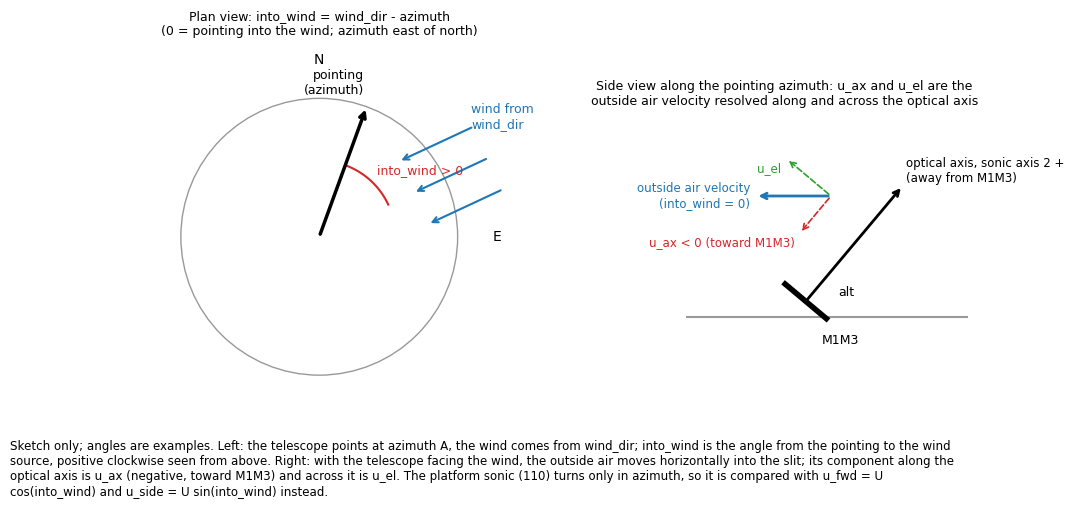

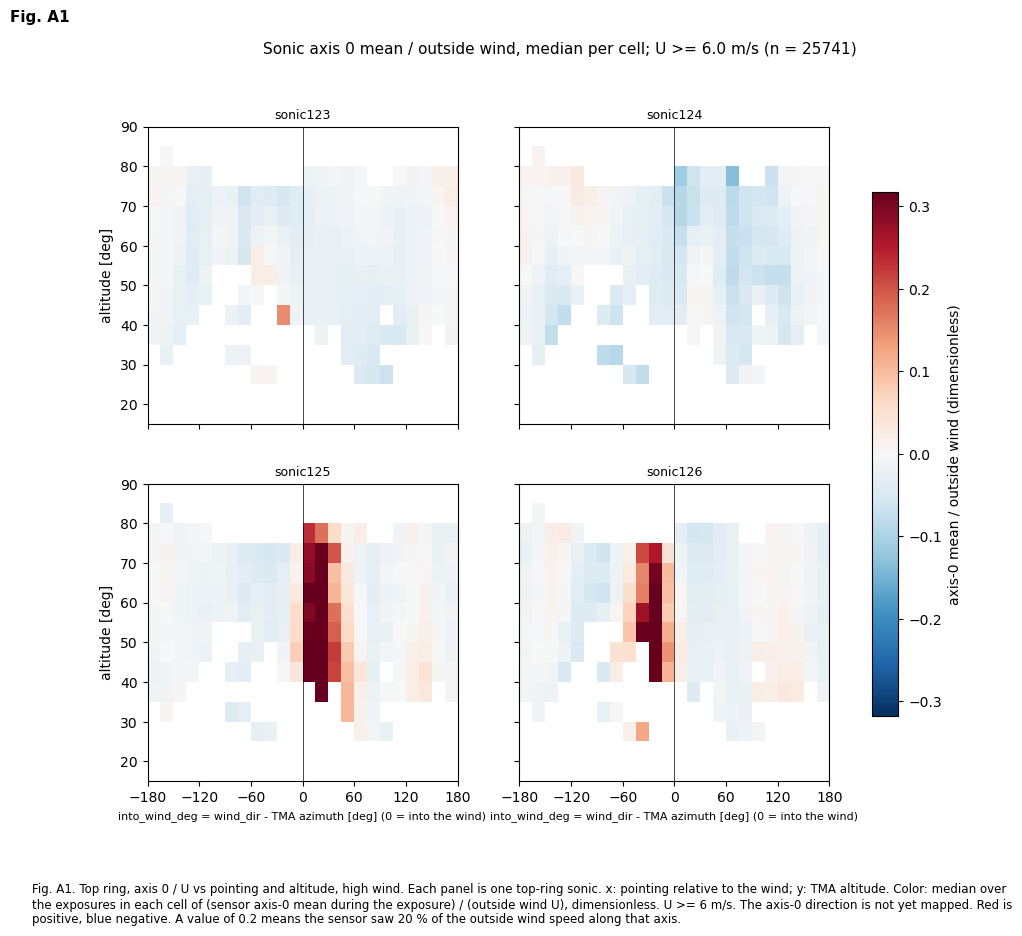

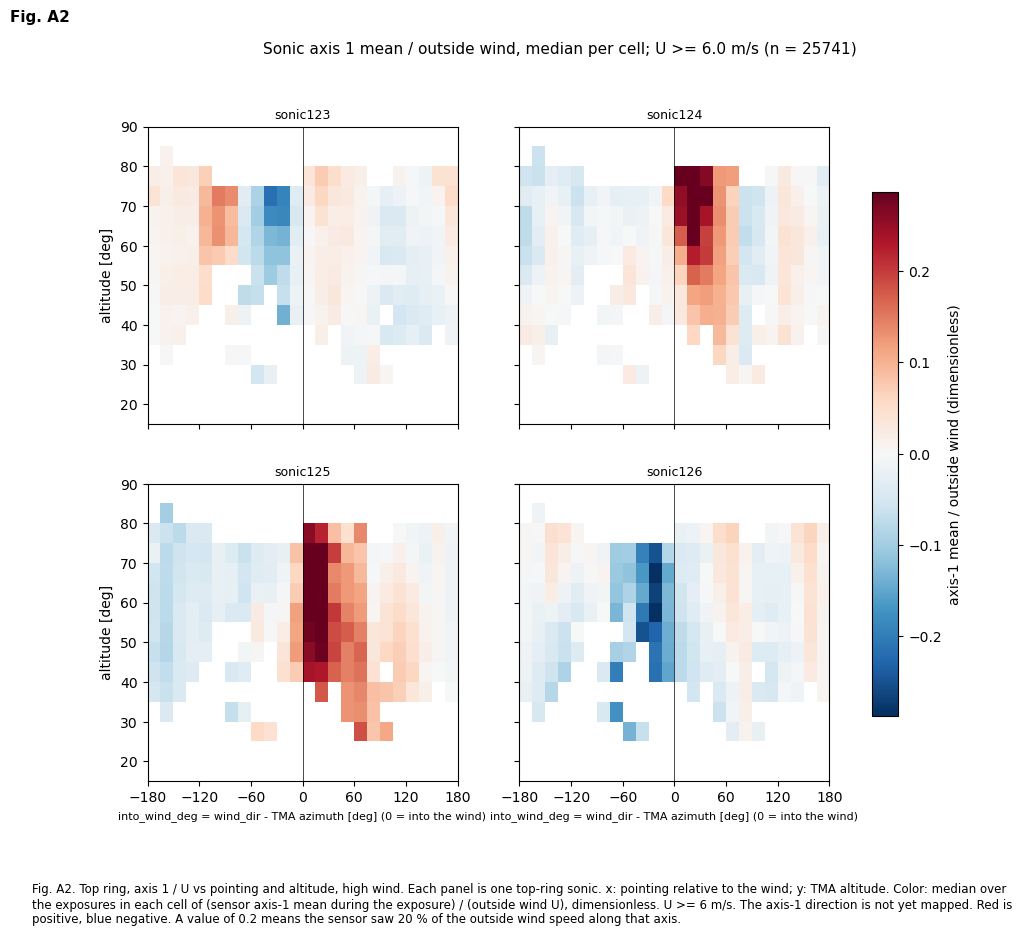

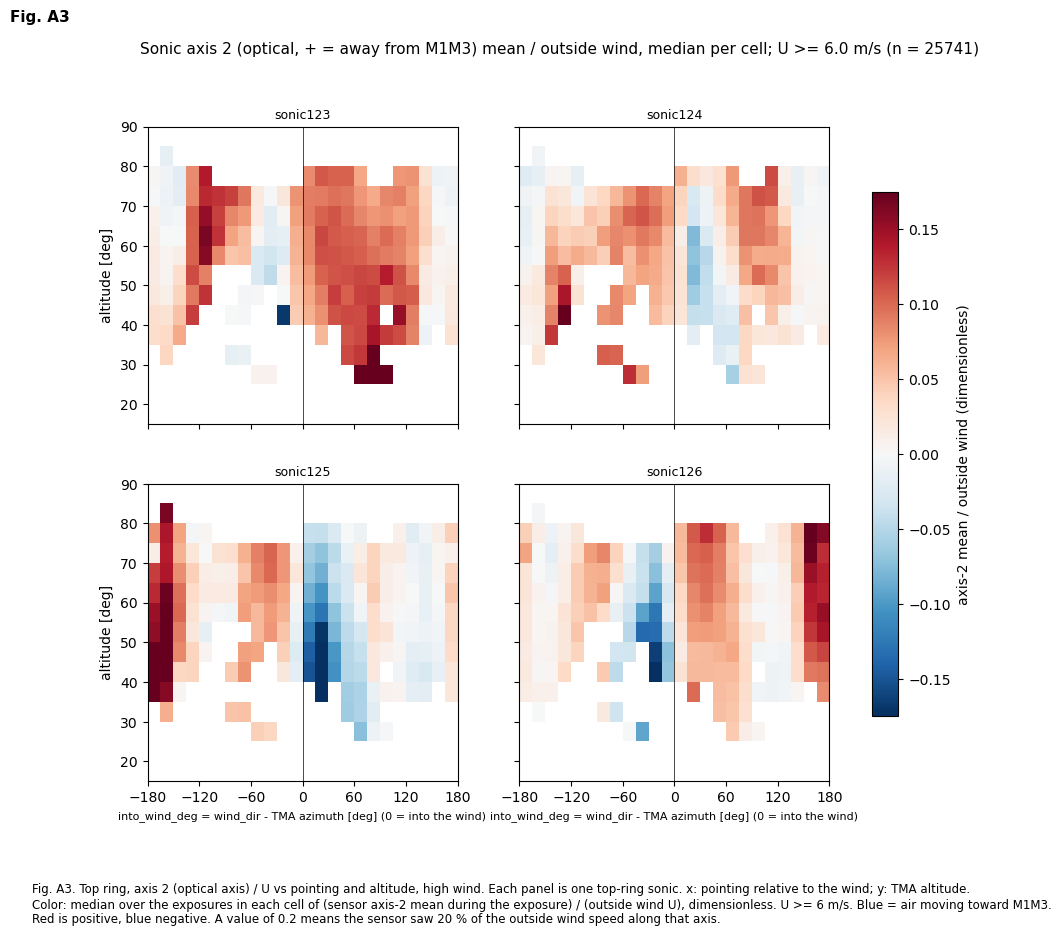

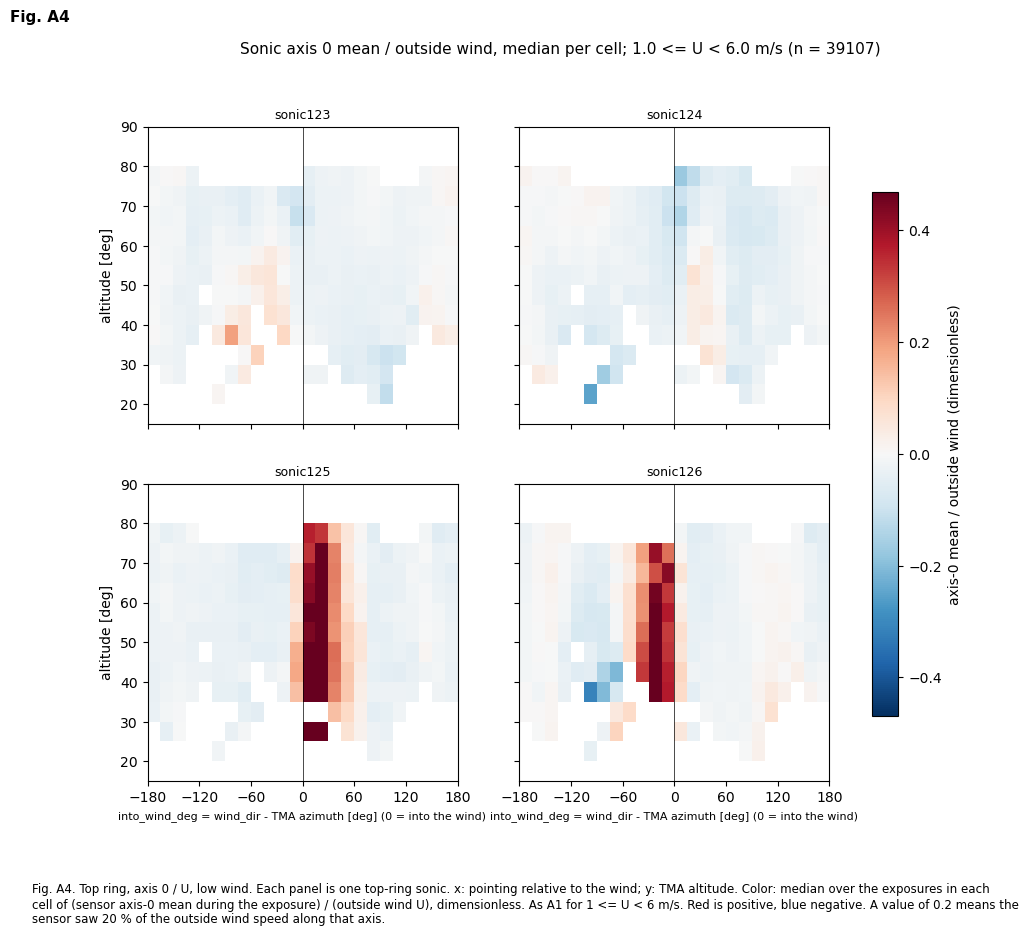

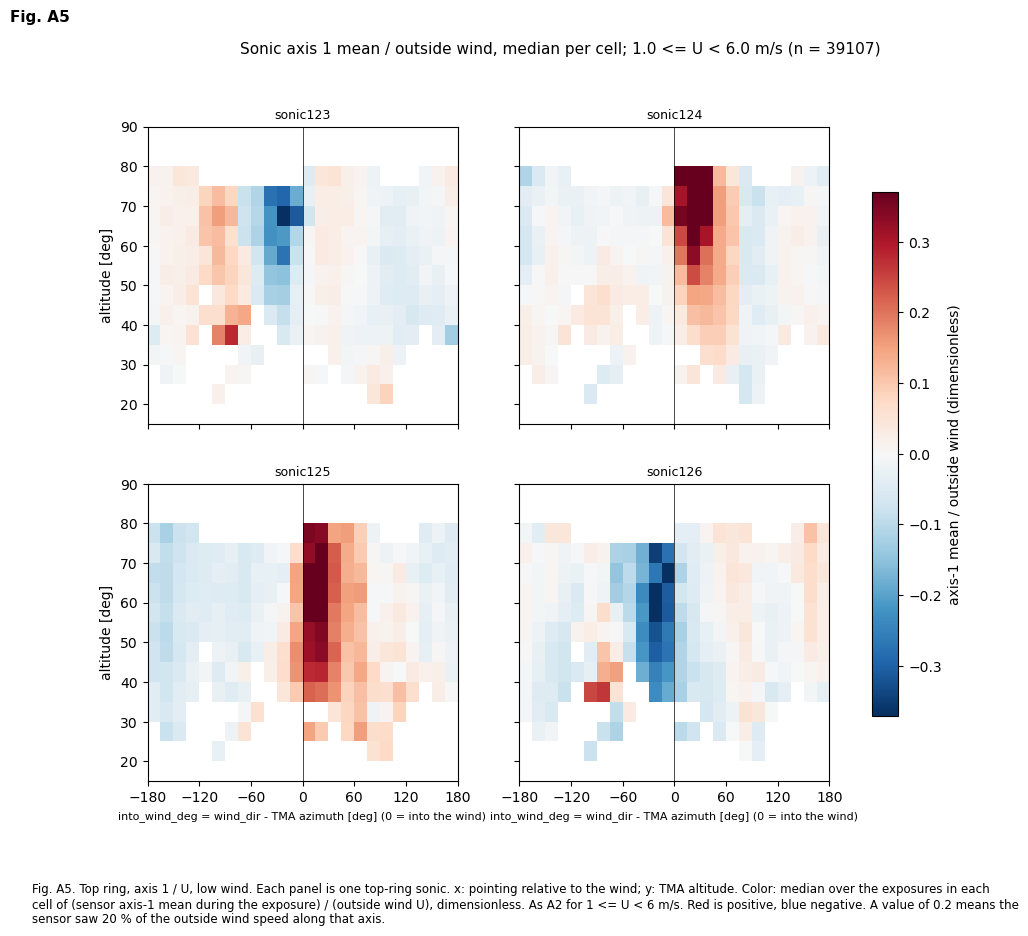

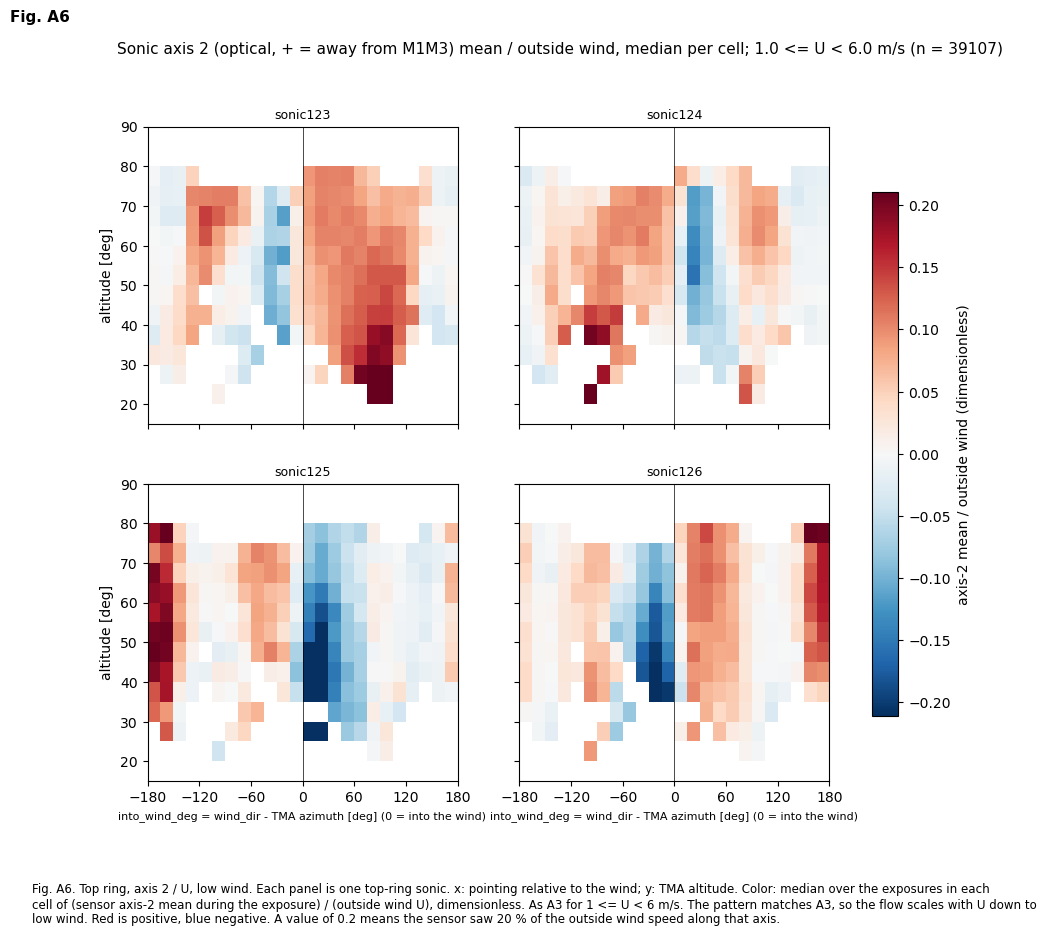

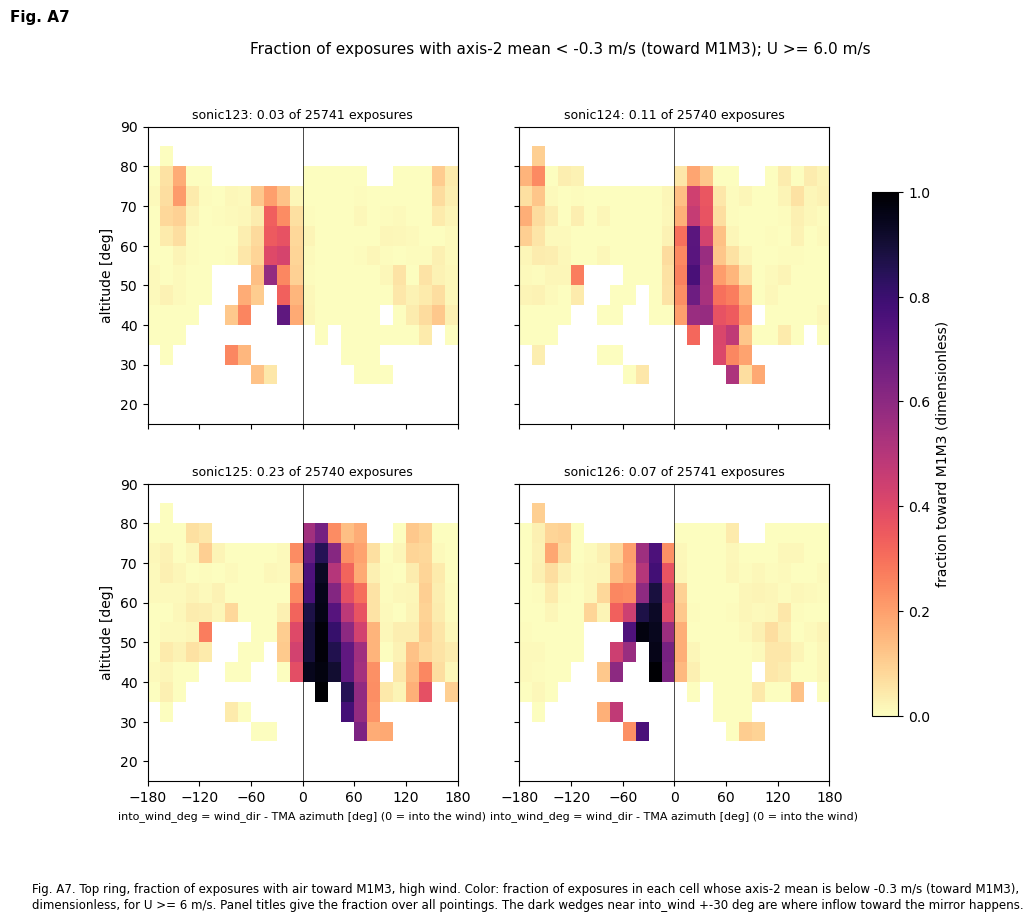

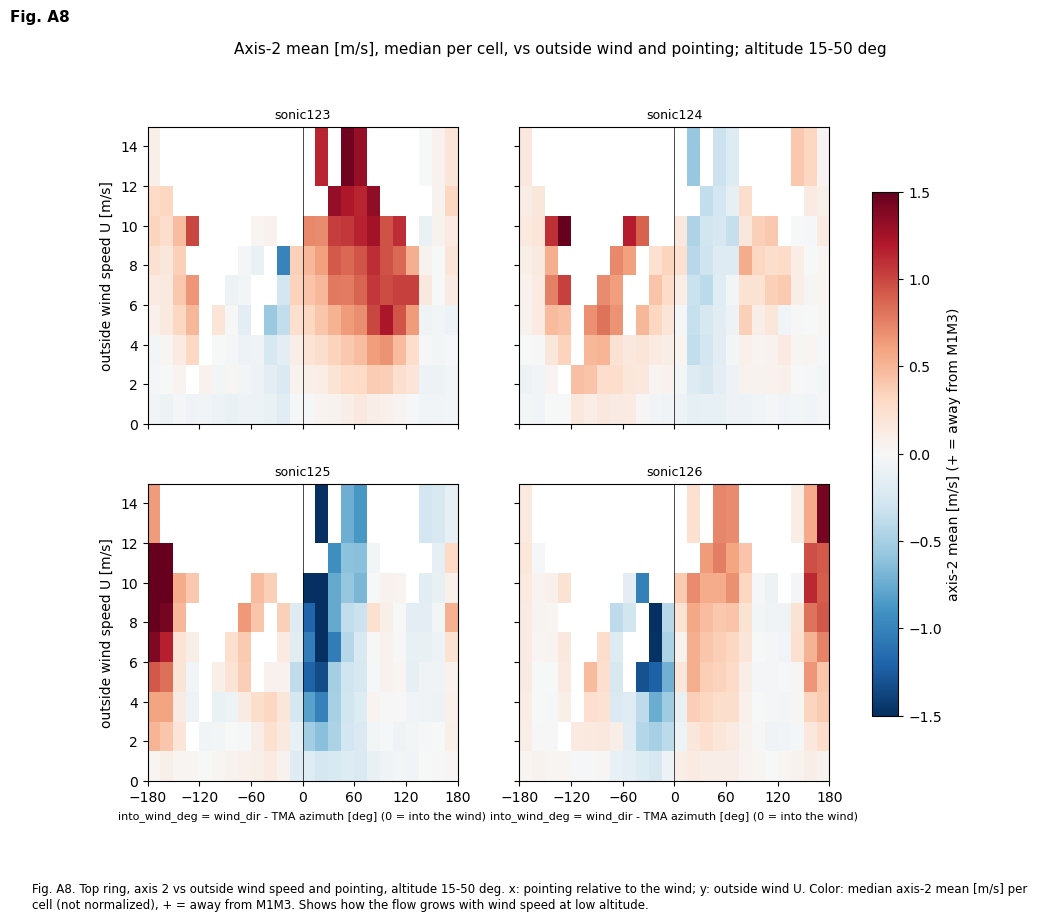

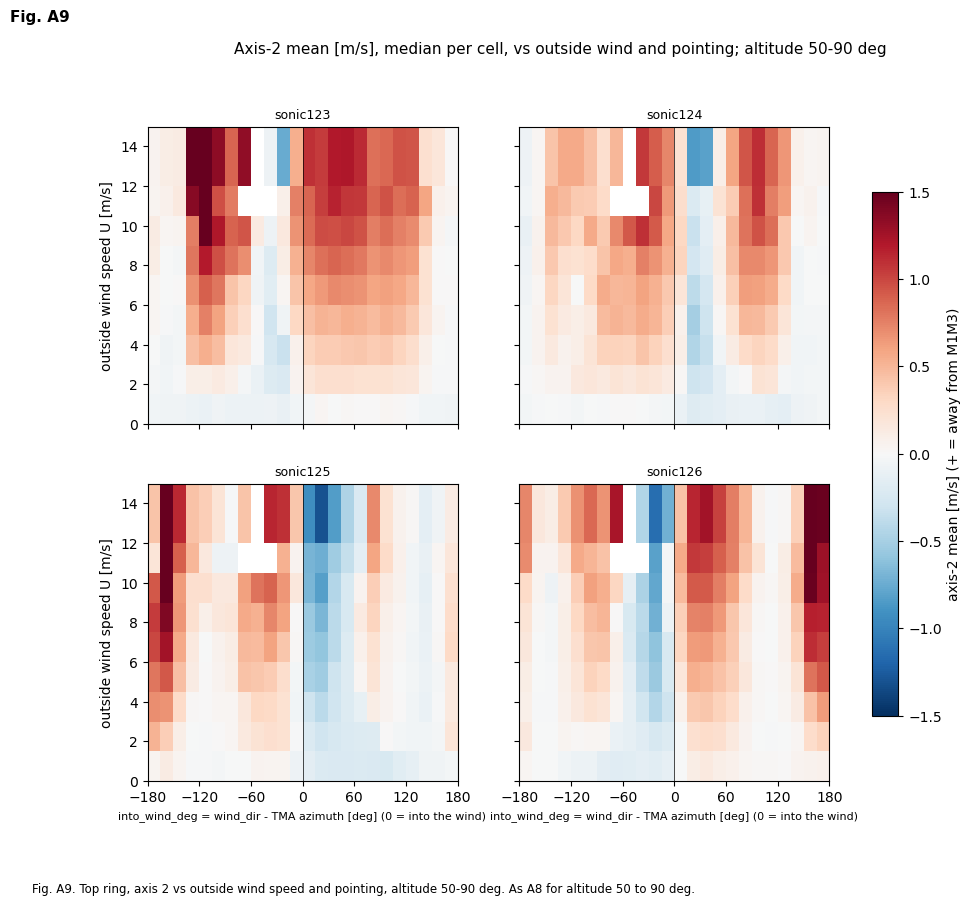

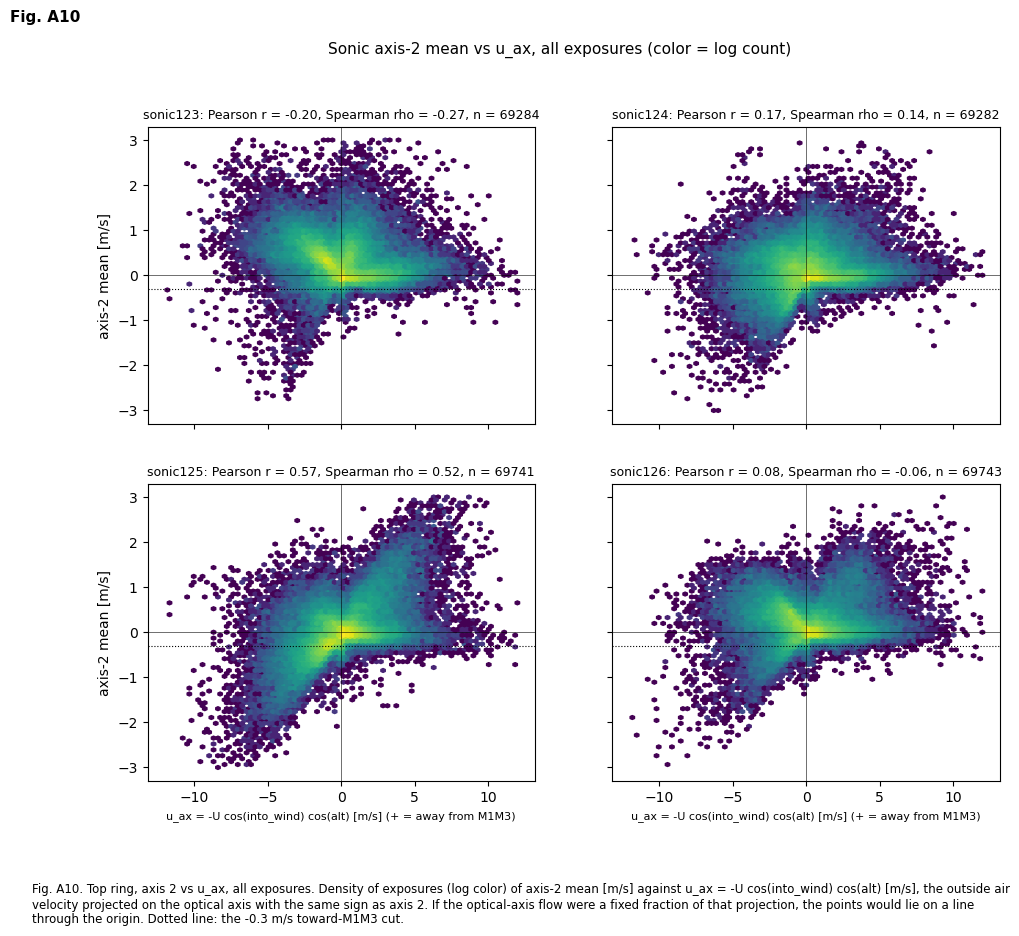

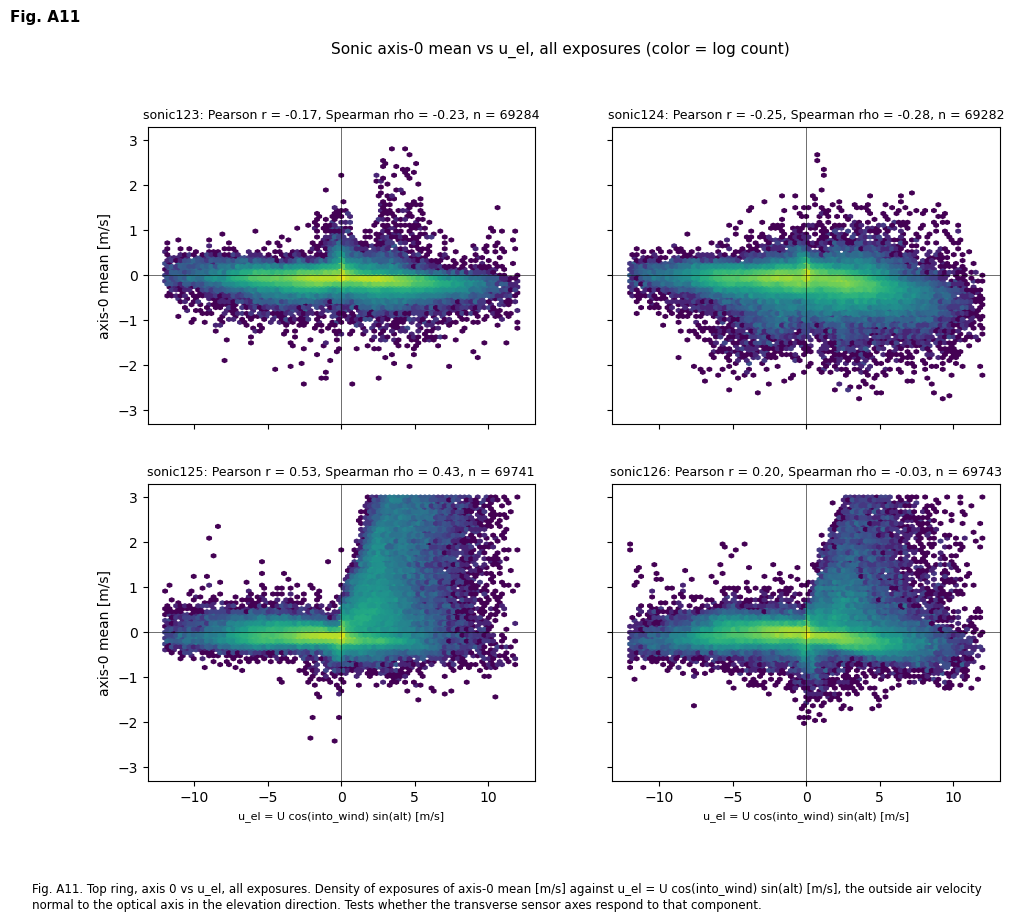

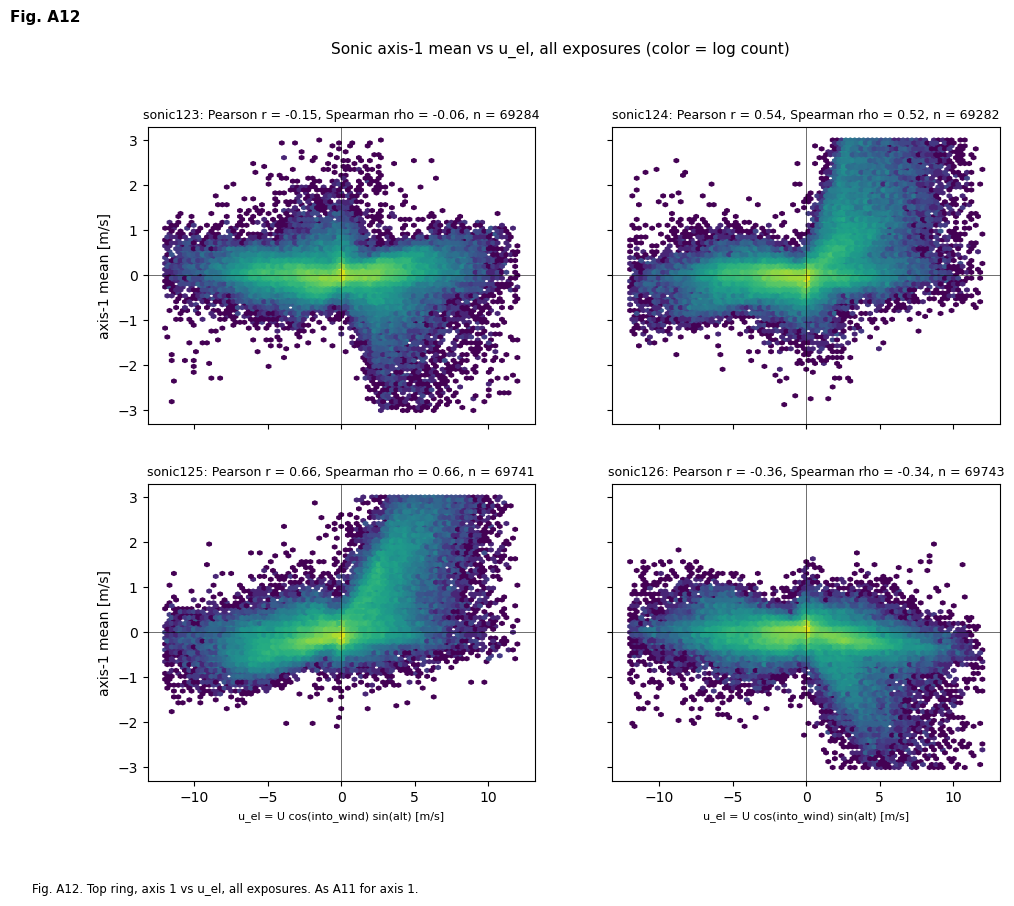

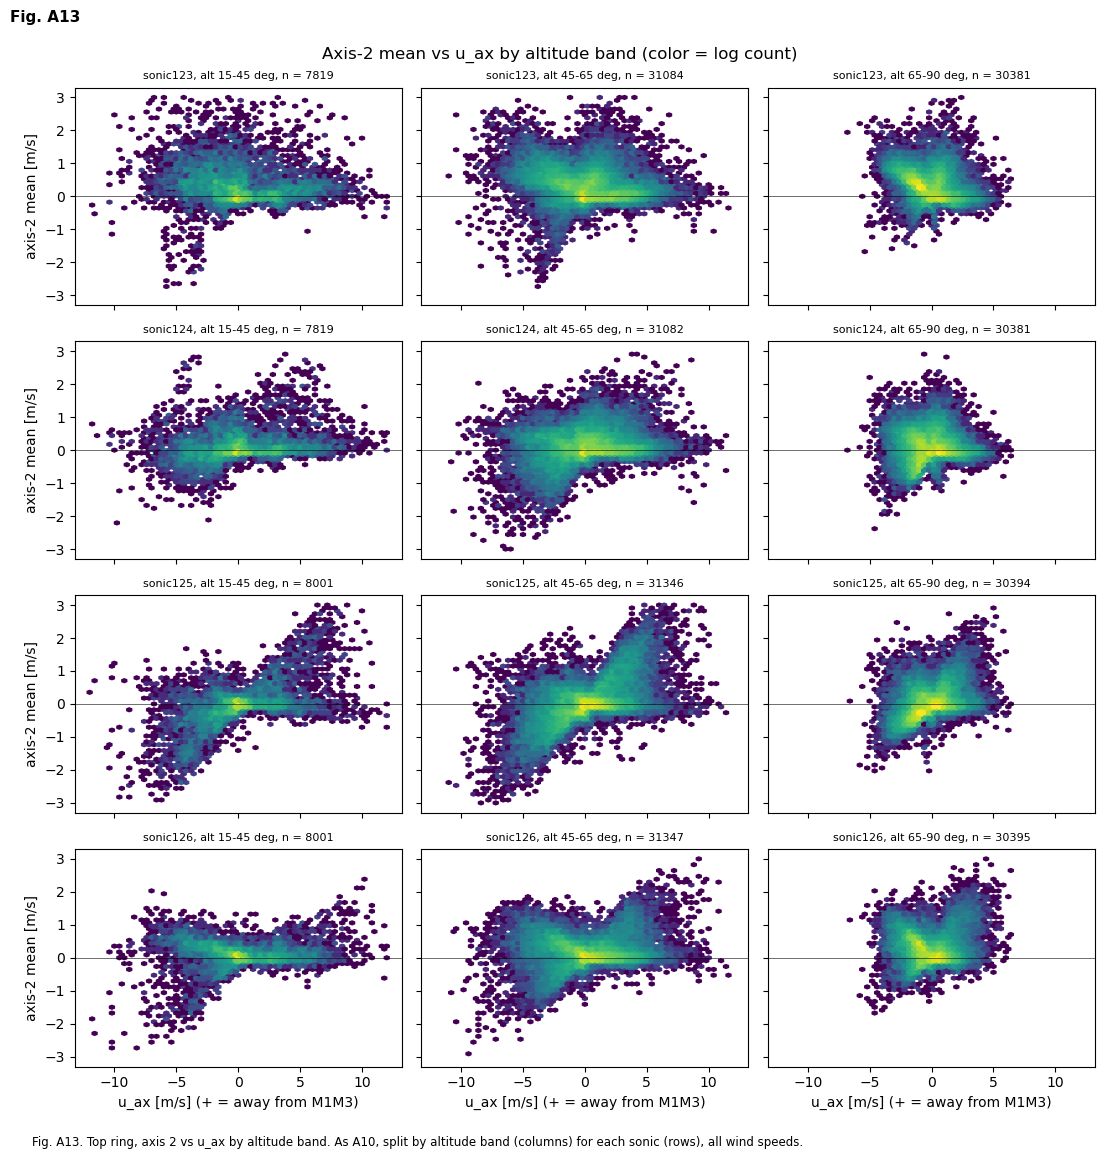

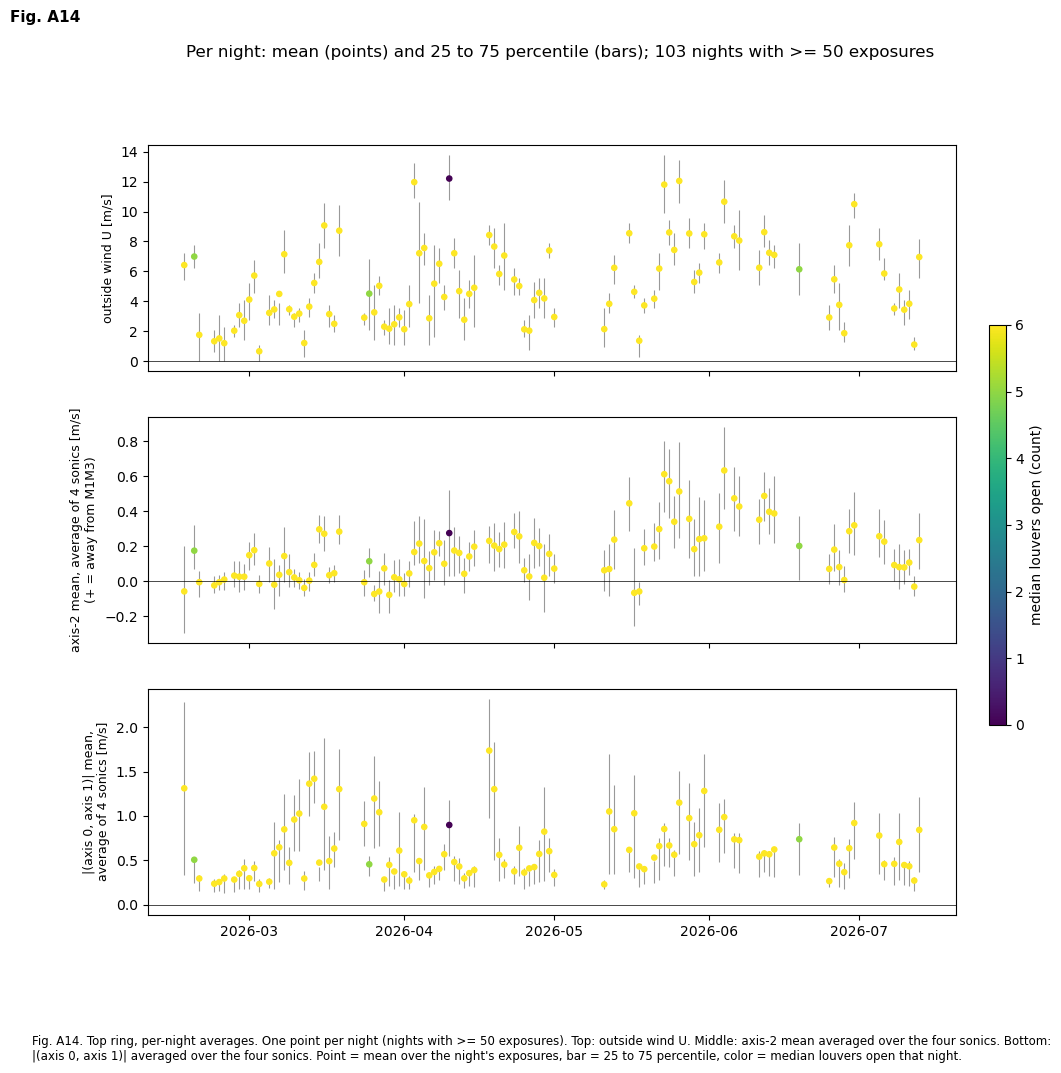

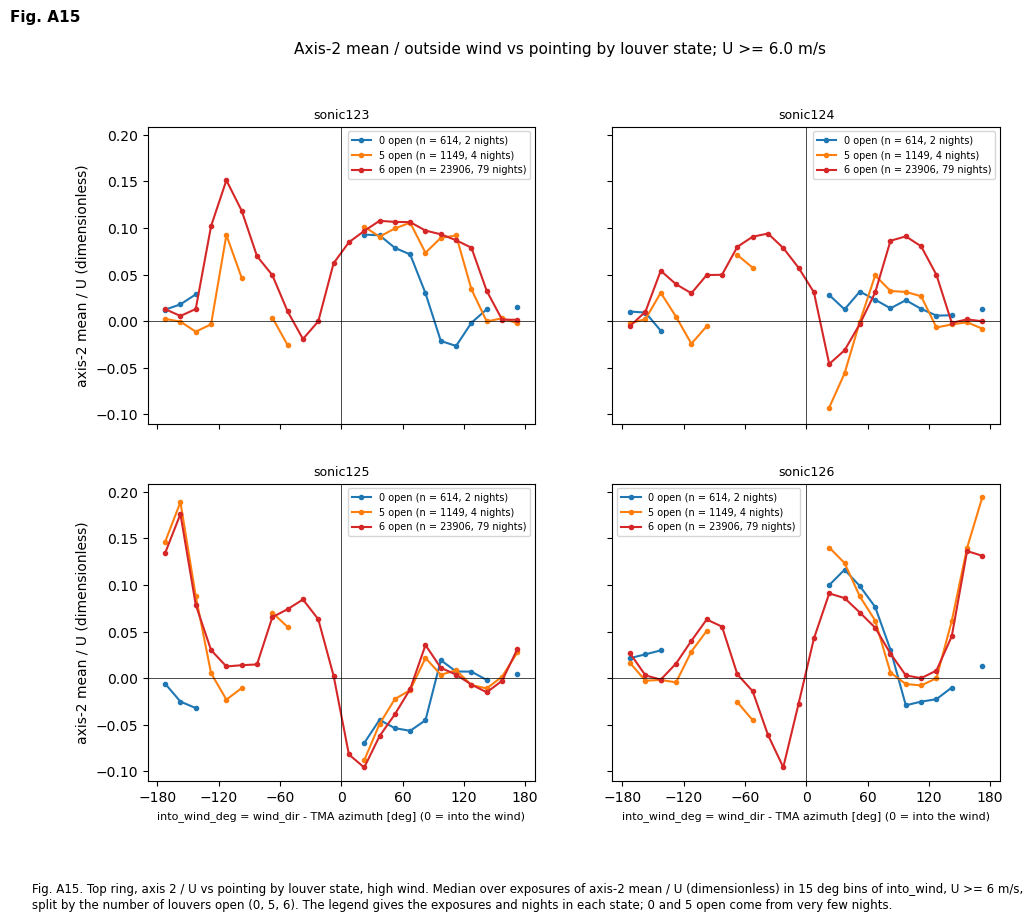

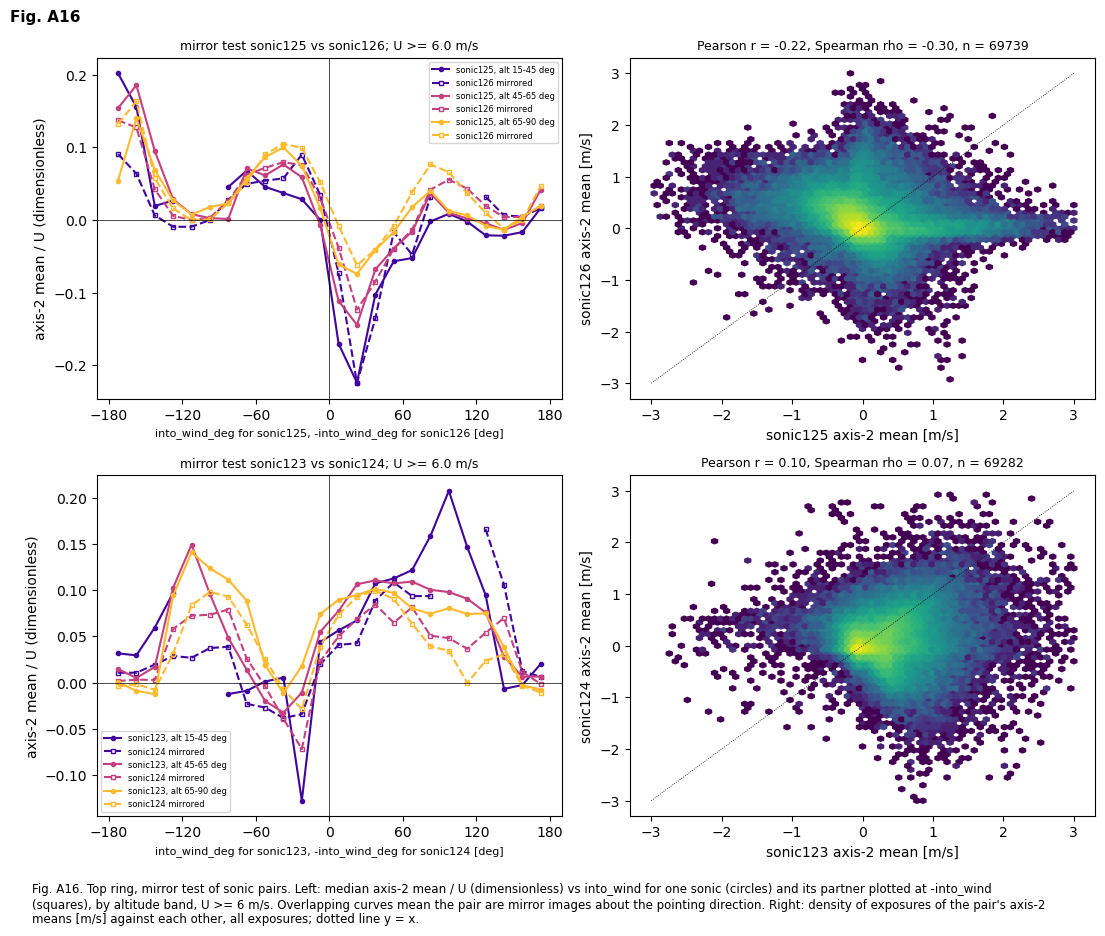

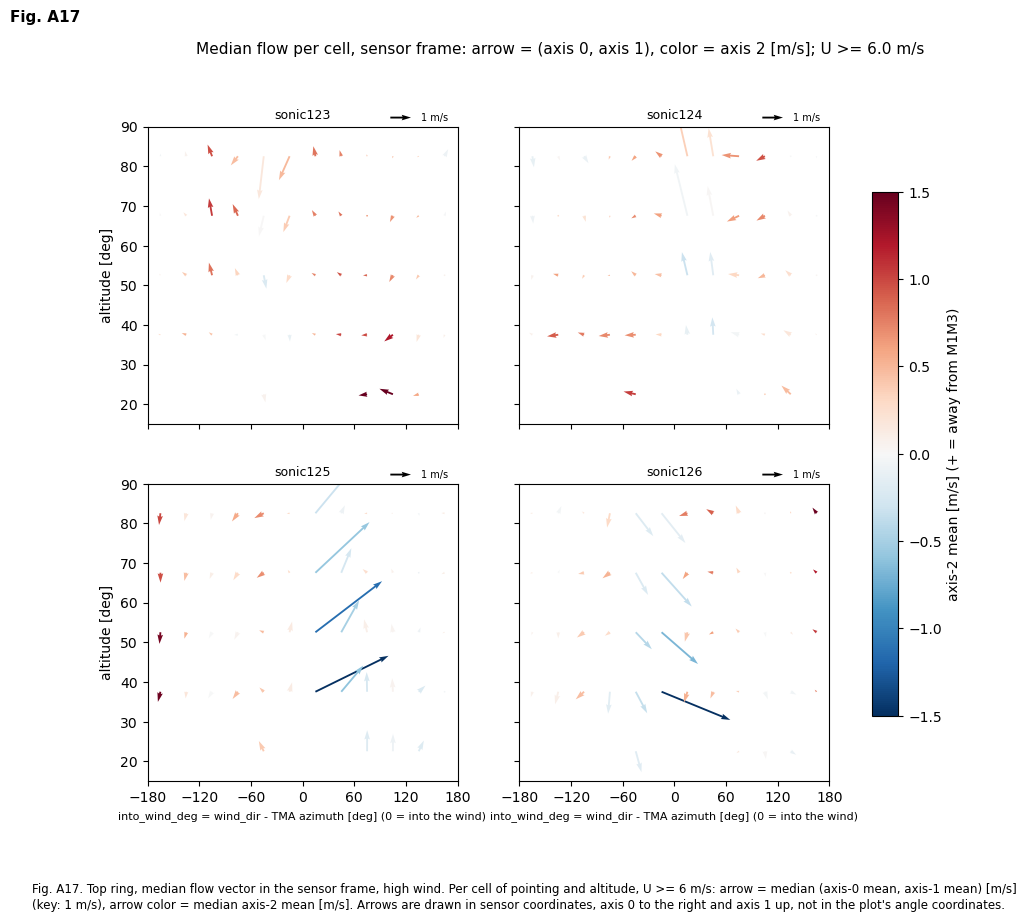

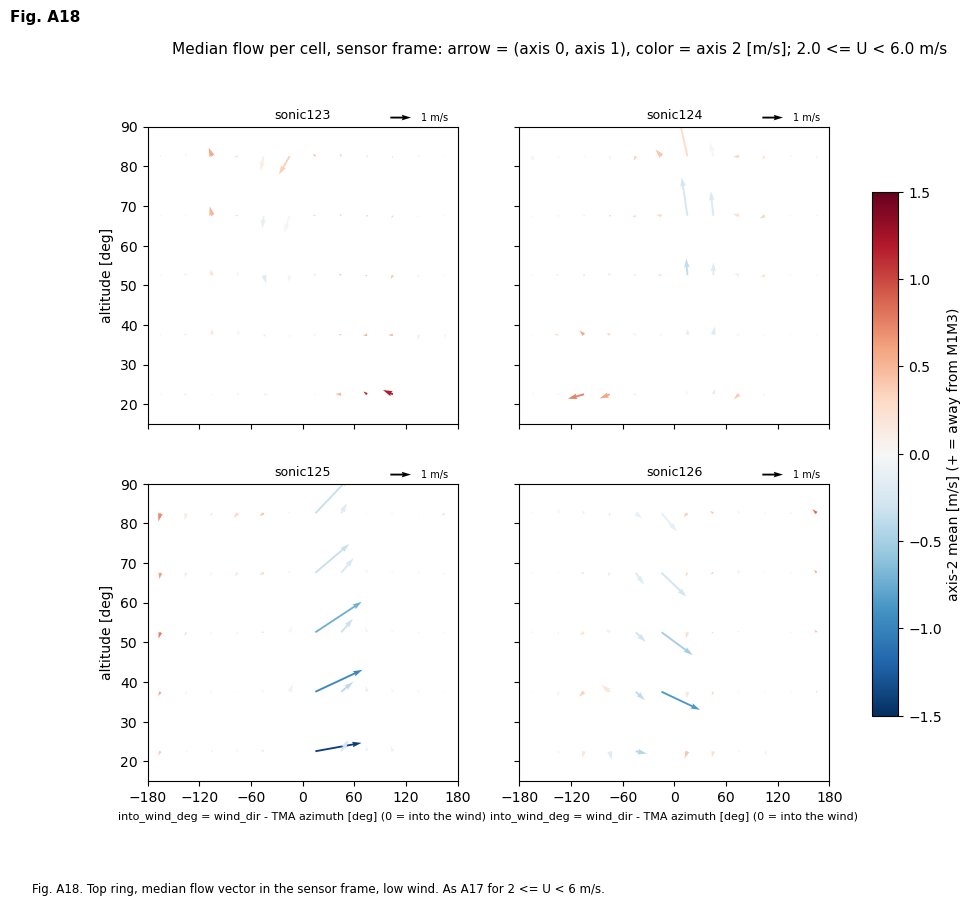

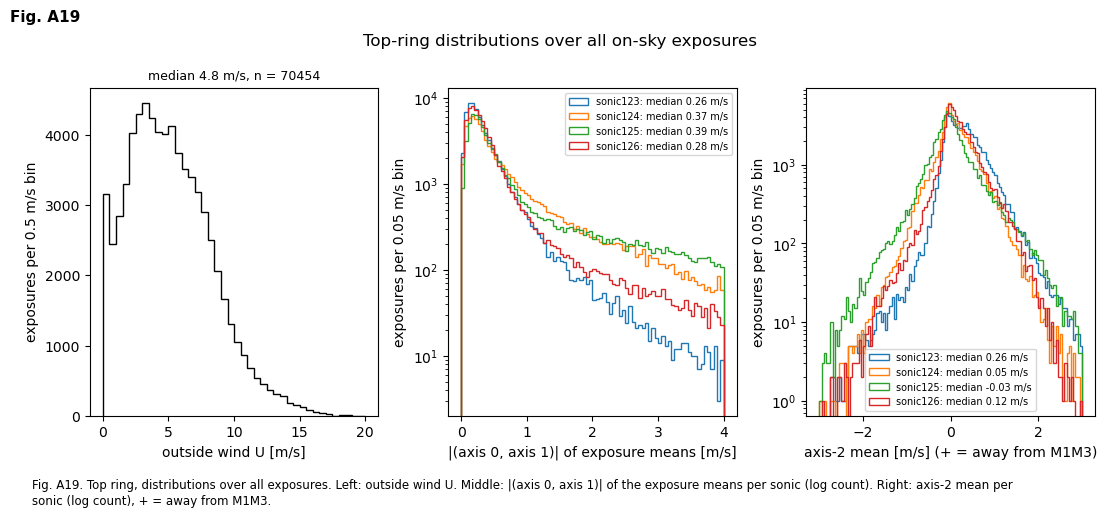

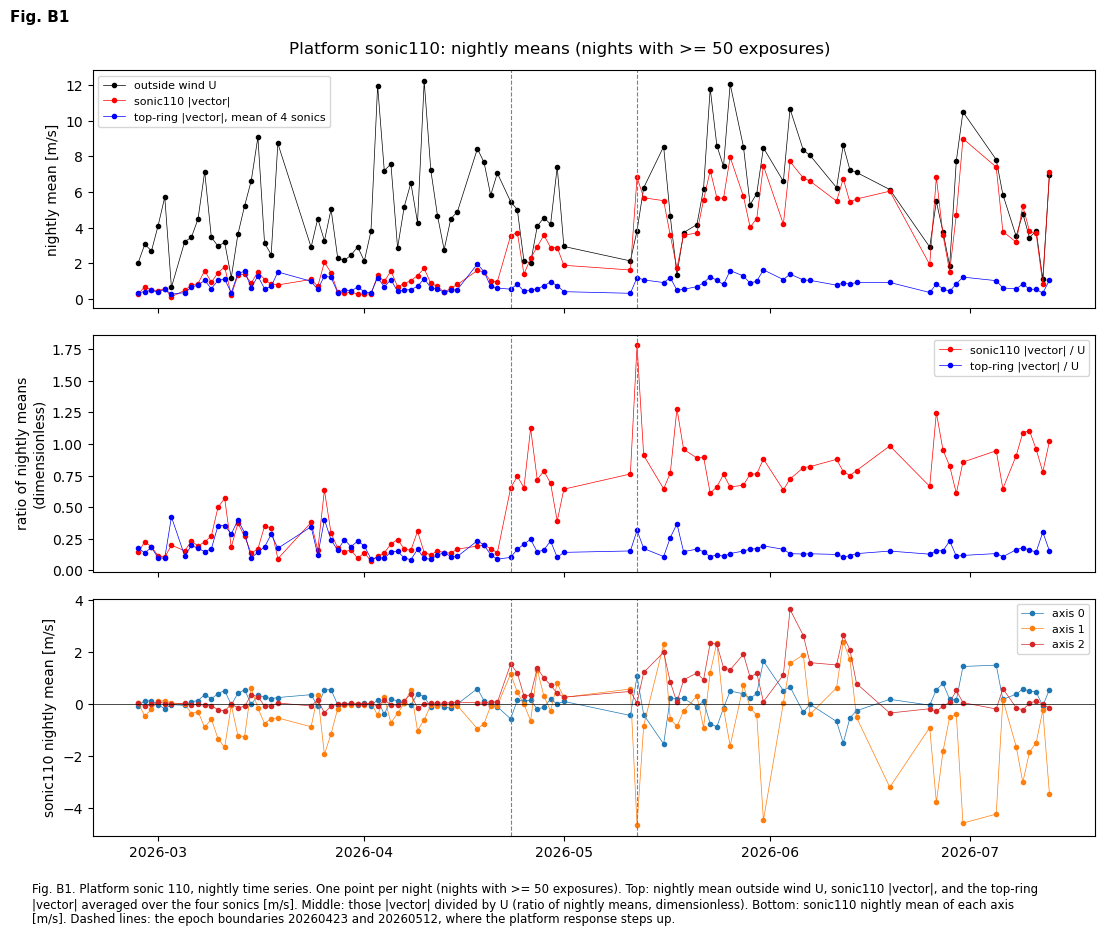

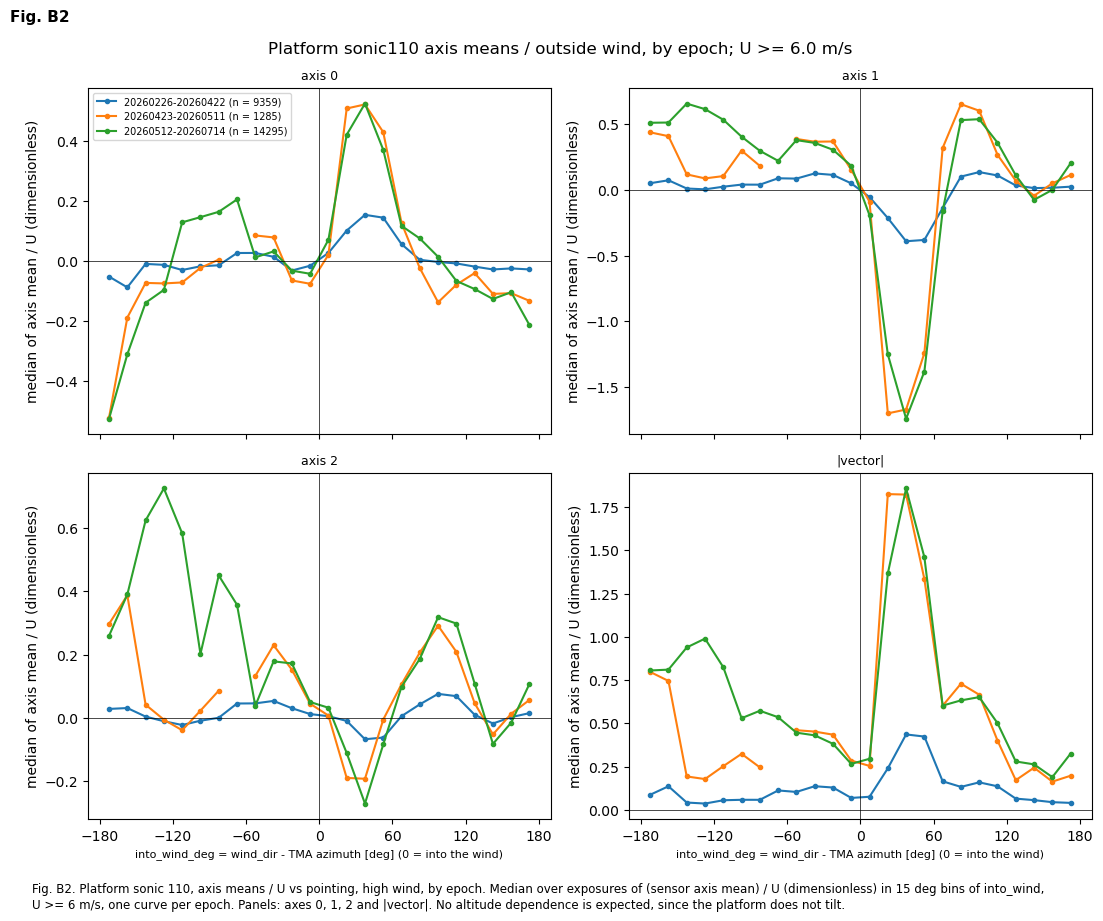

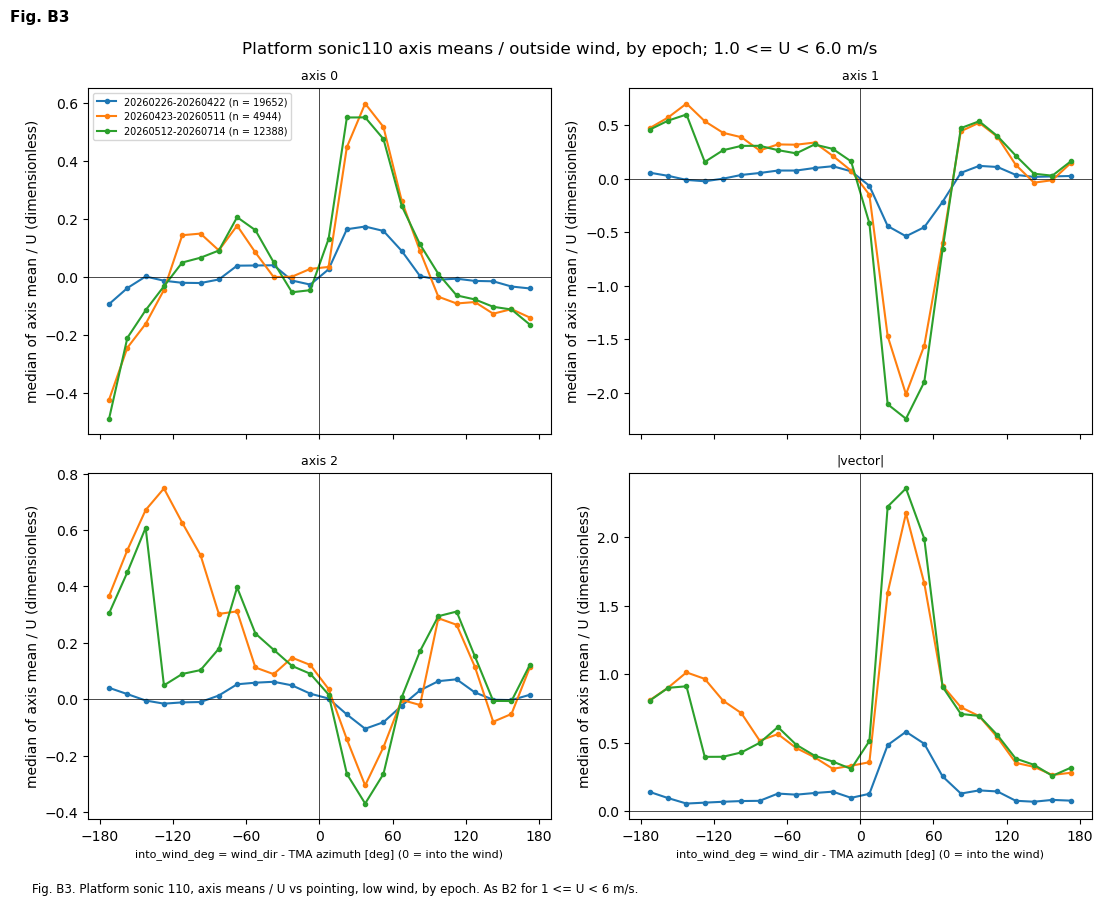

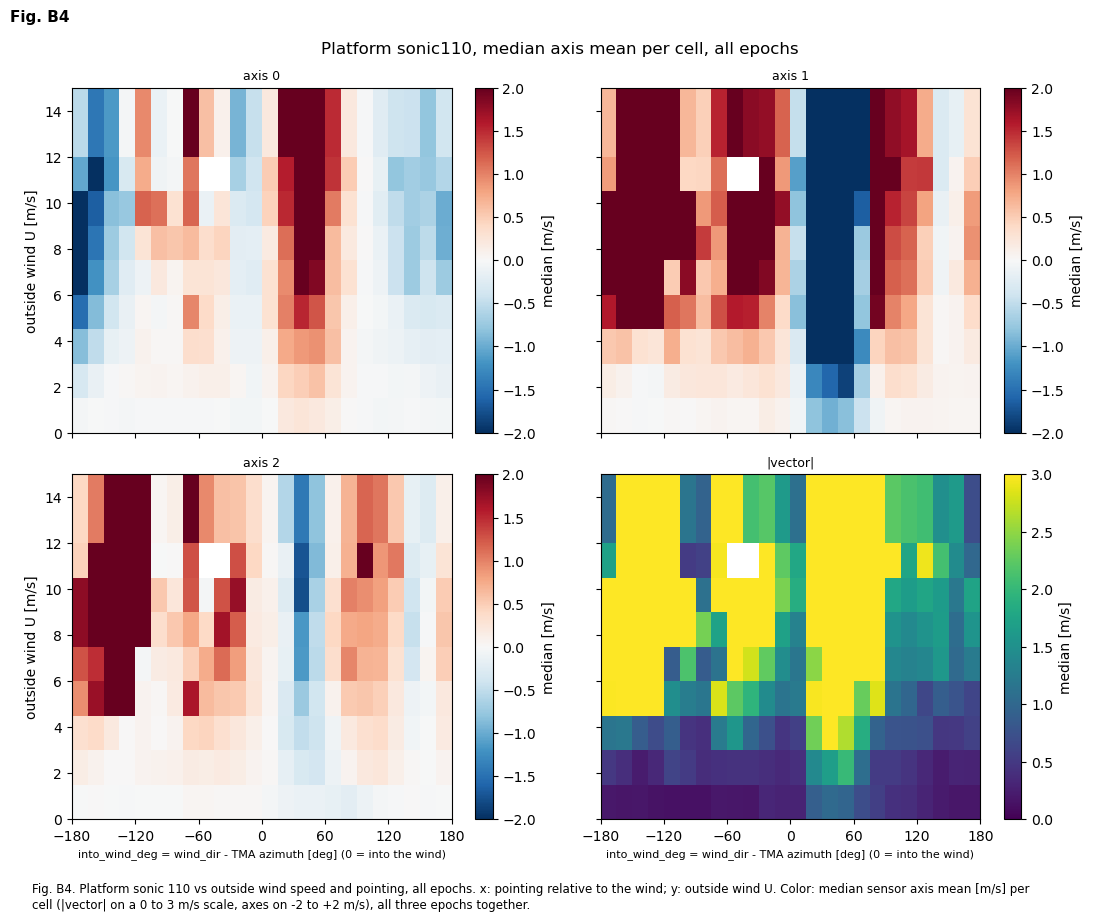

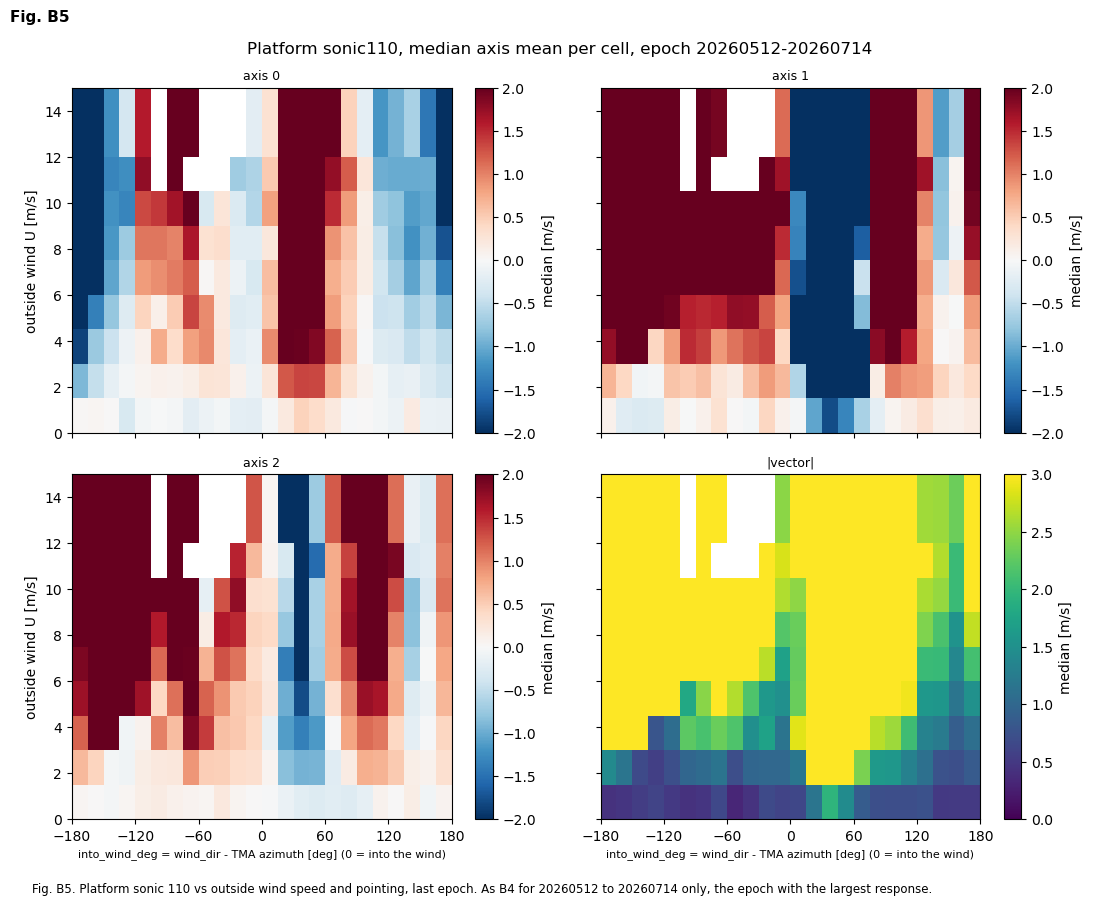

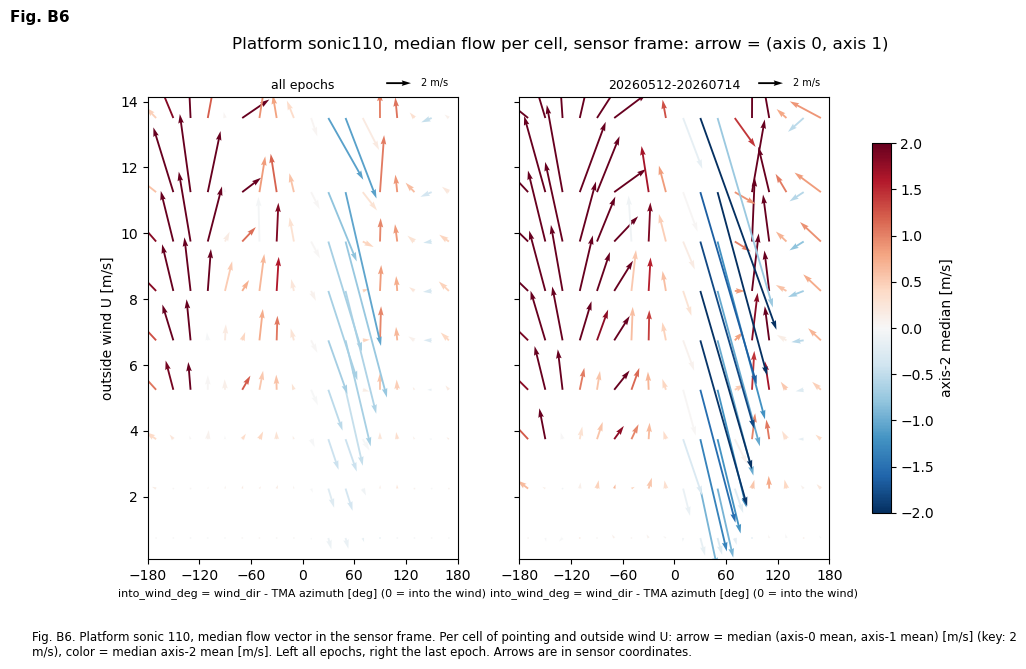

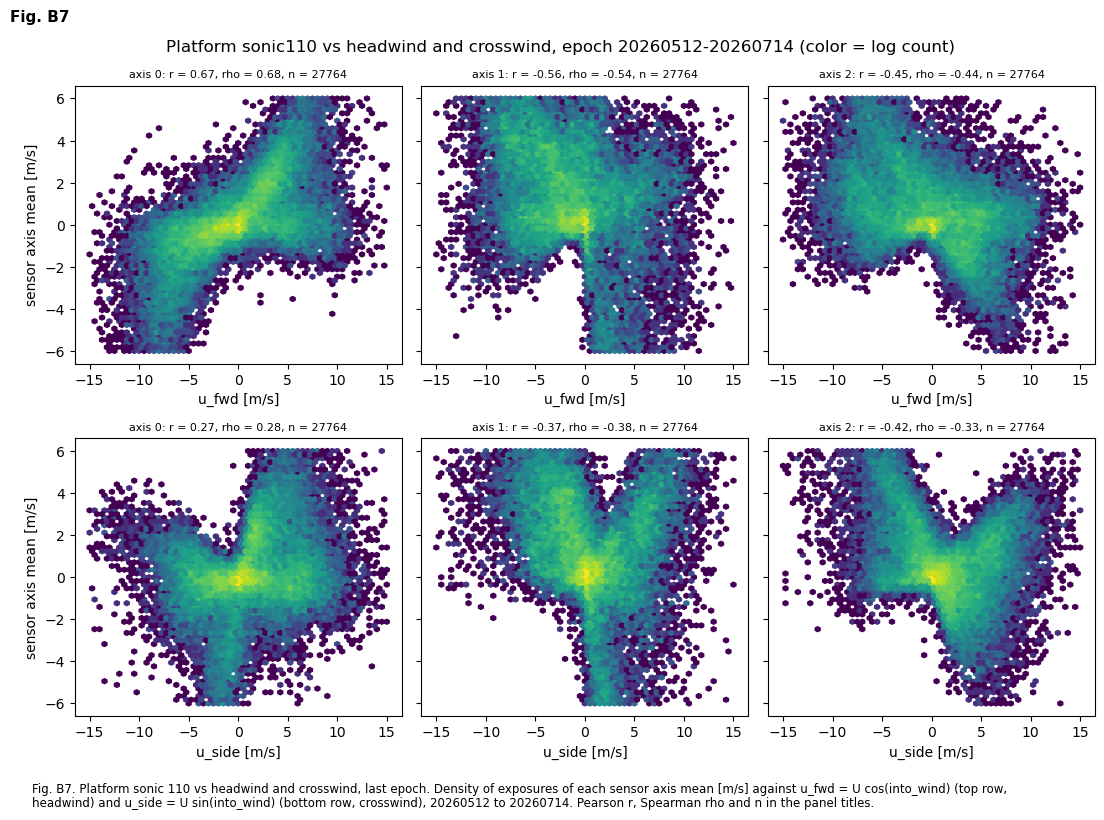

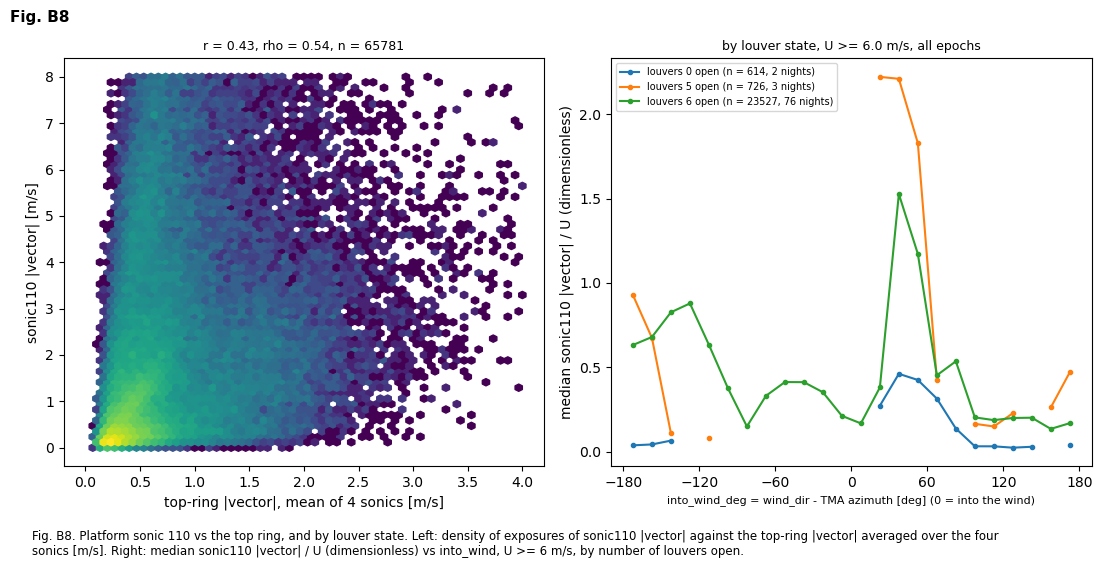

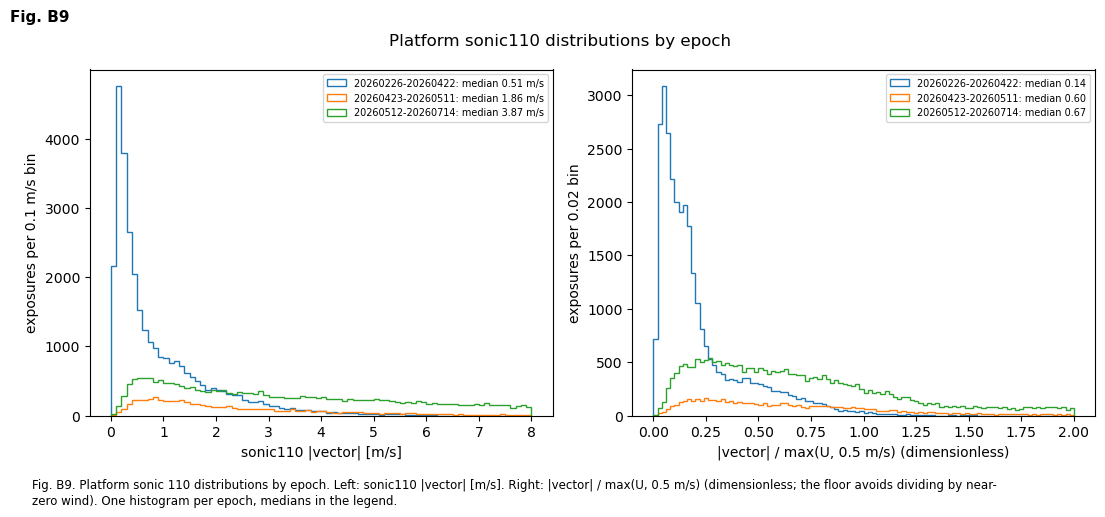

<Figure size 1100x850 with 0 Axes>

<Figure size 1100x850 with 0 Axes>

<Figure size 1100x850 with 0 Axes>

<Figure size 1100x850 with 0 Axes>

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/airflow/airflow_correlations/20261106_airflow_report/airflow_report.pdf


In [7]:
te = np.arange(-180, 181, ANGLE_STEP)
ae = np.arange(15, 91, ALT_STEP)
ue = np.array(U_EDGES, float)
xt = np.arange(-180, 181, 60)
pdf = PdfPages(PDF)

# Page 1: summary and contents; page 2: definitions
prose_page('TMA sonic anemometers versus outside wind', SUMMARY, size=8.8)
prose_page('Contents', 'Page 3: data and definitions. Page 4: geometry sketch. Figures follow in this order, '
           'each with an ID at top left and a caption below; tables T1 to T3 are at the end.\n\n'
           + '\n'.join(f'  {k:4s} {v[0]}' for k, v in CAPS.items()), size=9.5)
prose_page('What is plotted: data and definitions', DEFS, size=8.6)

# Page 3: geometry sketch
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.5))
A, D = np.radians(20), np.radians(65)   # example pointing azimuth and wind_dir
a1.set_aspect('equal'); a1.set_xlim(-1.4, 1.4); a1.set_ylim(-1.4, 1.4); a1.axis('off')
a1.add_patch(plt.Circle((0, 0), 1.0, fill=False, color='0.6'))
a1.annotate('N', (0, 1.25), ha='center'); a1.annotate('E', (1.25, 0), va='center')
a1.annotate('', (np.sin(A), np.cos(A)), (0, 0), arrowprops=dict(arrowstyle='->', lw=2.5, color='k'))
a1.text(1.1 * np.sin(A) - 0.05, 1.1 * np.cos(A), 'pointing\n(azimuth)', ha='right', fontsize=9)
for f in np.linspace(-0.25, 0.25, 3):
    x0, y0 = 1.35 * np.sin(D) + f * np.cos(D), 1.35 * np.cos(D) - f * np.sin(D)
    a1.annotate('', (x0 - 0.6 * np.sin(D), y0 - 0.6 * np.cos(D)), (x0, y0),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='tab:blue'))
a1.text(1.1 * np.sin(D) + 0.1, 1.1 * np.cos(D) + 0.32, 'wind from\nwind_dir', color='tab:blue', fontsize=9)
arc = np.linspace(A, D, 30)
a1.plot(0.55 * np.sin(arc), 0.55 * np.cos(arc), color='tab:red')
a1.text(0.62 * np.sin((A + D) / 2), 0.62 * np.cos((A + D) / 2), 'into_wind > 0', color='tab:red', fontsize=9)
a1.set_title('Plan view: into_wind = wind_dir - azimuth\n(0 = pointing into the wind; azimuth east of north)',
             fontsize=9)
alt = np.radians(50)
a2.set_aspect('equal'); a2.set_xlim(-1.4, 2.2); a2.set_ylim(-0.4, 1.9); a2.axis('off')
a2.plot([-0.5, 2.1], [0, 0], color='0.6')
o = np.array([0.6, 0.15]); pv = np.array([np.cos(alt), np.sin(alt)]); ev = np.array([-np.sin(alt), np.cos(alt)])
a2.plot(*np.c_[o - 0.25 * ev, o + 0.25 * ev], color='k', lw=4)
a2.text(*(o - 0.42 * ev + [0, -0.12]), 'M1M3', fontsize=9, ha='center')
a2.annotate('', o + 1.4 * pv, o, arrowprops=dict(arrowstyle='->', lw=2, color='k'))
a2.text(*(o + 1.45 * pv), 'optical axis, sonic axis 2 +\n(away from M1M3)', fontsize=8.5, ha='left')
a2.text(o[0] + 0.3, o[1] + 0.05, 'alt', fontsize=9)
c = o + 0.9 * pv + 0.45 * ev
v = np.array([-1.0, 0.0]) * 0.7   # pointing into the wind: air moves horizontally toward the mirror side
a2.annotate('', c + v, c, arrowprops=dict(arrowstyle='->', lw=2, color='tab:blue'))
a2.text(*(c + v + [-0.05, 0]), 'outside air velocity\n(into_wind = 0)', color='tab:blue', fontsize=8.5,
        ha='right', va='center')
for vec, lab, col in ((pv * (v @ pv), 'u_ax < 0 (toward M1M3)', 'tab:red'),
                      (ev * (v @ ev), 'u_el', 'tab:green')):
    a2.annotate('', c + vec, c, arrowprops=dict(arrowstyle='->', lw=1.2, color=col, ls='--'))
    a2.text(*(c + vec + [-0.05, -0.12]), lab, color=col, fontsize=8.5, ha='right')
a2.set_title('Side view along the pointing azimuth: u_ax and u_el are the\noutside air velocity resolved along '
             'and across the optical axis', fontsize=9)
fig.text(0.02, 0.02, wrap('Sketch only; angles are examples. Left: the telescope points at azimuth A, the wind '
                          'comes from wind_dir; into_wind is the angle from the pointing to the wind source, '
                          'positive clockwise seen from above. Right: with the telescope facing the wind, the '
                          'outside air moves horizontally into the slit; its component along the optical axis '
                          'is u_ax (negative, toward M1M3) and across it is u_el. The platform sonic (110) '
                          'turns only in azimuth, so it is compared with u_fwd = U cos(into_wind) and '
                          'u_side = U sin(into_wind) instead.', 160), fontsize=8.5, va='bottom')
pdf.savefig(fig, bbox_inches='tight'); plt.show()

# A1-A6: heat maps of axis mean / U, altitude vs into_wind; high then low wind
fid = iter(['A1', 'A2', 'A3', 'A4', 'A5', 'A6'])
for ws, wlab in ((w, f'U >= {WIND_MIN} m/s'), (wlow, f'{WIND_LOW[0]} <= U < {WIND_LOW[1]} m/s')):
    for a in range(3):
        zs = [map2d(ws.into_wind_deg.to_numpy(), ws.altitude.to_numpy(),
                    (ws[f'sonic{i}_mean_{a}_ms'] / ws.wind_speed_ms).to_numpy(), te, ae)[0] for i in SONICS]
        vm = np.nanpercentile(np.abs(np.concatenate([z.ravel() for z in zs])), 98)
        fig, axs = four_panel(f'Sonic axis {a}' + (' (optical, + = away from M1M3)' if a == 2 else '')
                              + f' mean / outside wind, median per cell; {wlab} (n = {len(ws)})')
        for ax, i, z in zip(axs.flat, SONICS, zs):
            pc = ax.pcolormesh(te, ae, z, cmap='RdBu_r', vmin=-vm, vmax=vm)
            ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
        fig.colorbar(pc, ax=axs, label=f'axis-{a} mean / outside wind (dimensionless)', shrink=0.8)
        for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
        for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
        save(fig, next(fid))

# A7: probability toward M1M3
fig, axs = four_panel(f'Fraction of exposures with axis-2 mean < {TOWARD_CUT} m/s (toward M1M3); U >= {WIND_MIN} m/s')
for ax, i in zip(axs.flat, SONICS):
    y = w[f'sonic{i}_mean_2_ms'].to_numpy()
    z, n = map2d(w.into_wind_deg.to_numpy(), w.altitude.to_numpy(),
                 np.where(np.isfinite(y), (y < TOWARD_CUT).astype(float), np.nan), te, ae, 'mean')
    pc = ax.pcolormesh(te, ae, z, cmap='magma_r', vmin=0, vmax=1)
    ax.set_title(f'sonic{i}: {np.nanmean(y < TOWARD_CUT):.2f} of {np.isfinite(y).sum()} exposures', fontsize=9)
    ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
fig.colorbar(pc, ax=axs, label='fraction toward M1M3 (dimensionless)', shrink=0.8)
for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
save(fig, 'A7')

# A8-A9: onset with wind speed
for fid_, (lo, hi) in zip(('A8', 'A9'), ((15, ALT_SPLIT), (ALT_SPLIT, 90))):
    s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
    fig, axs = four_panel(f'Axis-2 mean [m/s], median per cell, vs outside wind and pointing; altitude {lo}-{hi} deg')
    for ax, i in zip(axs.flat, SONICS):
        z, n = map2d(s_.into_wind_deg.to_numpy(), s_.wind_speed_ms.to_numpy(),
                     s_[f'sonic{i}_mean_2_ms'].to_numpy(), te, ue)
        pc = ax.pcolormesh(te, ue, z, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
        ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
    fig.colorbar(pc, ax=axs, label='axis-2 mean [m/s] (+ = away from M1M3)', shrink=0.8)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('outside wind speed U [m/s]')
    save(fig, fid_)

# A10-A12: axis 2 vs u_ax, axes 0 and 1 vs u_el
for fid_, a, xn, xlab in (('A10', 2, 'u_ax', 'u_ax = -U cos(into_wind) cos(alt) [m/s] (+ = away from M1M3)'),
                          ('A11', 0, 'u_el', 'u_el = U cos(into_wind) sin(alt) [m/s]'),
                          ('A12', 1, 'u_el', 'u_el = U cos(into_wind) sin(alt) [m/s]')):
    fig, axs = four_panel(f'Sonic axis-{a} mean vs {xn}, all exposures (color = log count)')
    for ax, i in zip(axs.flat, SONICS):
        x, y = d[xn], d[f'sonic{i}_mean_{a}_ms']; ok = x.notna() & y.notna()
        ax.hexbin(x[ok], y[ok], gridsize=80, bins='log', extent=(-12, 12, -3, 3), mincnt=1)
        ax.axhline(0, color='k', lw=0.4); ax.axvline(0, color='k', lw=0.4)
        if a == 2:
            ax.axhline(TOWARD_CUT, color='k', ls=':', lw=0.8)
        ax.set_title(f'sonic{i}: Pearson r = {stats.pearsonr(x[ok], y[ok])[0]:.2f}, Spearman rho = '
                     f'{stats.spearmanr(x[ok], y[ok])[0]:.2f}, n = {ok.sum()}', fontsize=9)
    for ax in axs[1]: ax.set_xlabel(xlab, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel(f'axis-{a} mean [m/s]')
    save(fig, fid_)

# A13: by altitude band
fig, axs = plt.subplots(4, 3, figsize=(11, 11), sharex=True, sharey=True)
for r_, i in enumerate(SONICS):
    for c_, (lo, hi) in enumerate(ALT_BANDS):
        s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
        y = s_[f'sonic{i}_mean_2_ms']; ok = y.notna()
        axs[r_, c_].hexbin(s_.u_ax[ok], y[ok], gridsize=60, bins='log', extent=(-12, 12, -3, 3), mincnt=1)
        axs[r_, c_].axhline(0, color='k', lw=0.4)
        axs[r_, c_].set_title(f'sonic{i}, alt {lo}-{hi} deg, n = {ok.sum()}', fontsize=8)
for ax in axs[-1]: ax.set_xlabel('u_ax [m/s] (+ = away from M1M3)')
for ax in axs[:, 0]: ax.set_ylabel('axis-2 mean [m/s]')
fig.suptitle('Axis-2 mean vs u_ax by altitude band (color = log count)'); fig.tight_layout()
save(fig, 'A13')

# A14: per night
dt = pd.to_datetime(nights.day_obs.astype(str))
fig, axs = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, k, lab in ((axs[0], 'U', 'outside wind U [m/s]'),
                   (axs[1], 'ax2', 'axis-2 mean, average of 4 sonics [m/s]\n(+ = away from M1M3)'),
                   (axs[2], 'perp', '|(axis 0, axis 1)| mean,\naverage of 4 sonics [m/s]')):
    ax.vlines(dt, nights[f'{k}_q25'], nights[f'{k}_q75'], color='0.6', lw=0.8, zorder=0)
    sc = ax.scatter(dt, nights[f'{k}_mean'], c=nights.louvers, cmap='viridis', vmin=0, vmax=6, s=14)
    ax.axhline(0, color='k', lw=0.5); ax.set_ylabel(lab, fontsize=9)
fig.subplots_adjust(right=0.86)
fig.colorbar(sc, cax=fig.add_axes([0.89, 0.3, 0.015, 0.4]), label='median louvers open (count)')
fig.suptitle(f'Per night: mean (points) and 25 to 75 percentile (bars); {len(nights)} nights with >= {NIGHT_MIN} exposures')
fig.autofmt_xdate()
save(fig, 'A14')

# A15: louver state
lcol = {'0 open': 'tab:blue', '5 open': 'tab:orange', '6 open': 'tab:red'}
fig, axs = four_panel(f'Axis-2 mean / outside wind vs pointing by louver state; U >= {WIND_MIN} m/s')
for ax, i in zip(axs.flat, SONICS):
    for lab, col in lcol.items():
        s_ = w[w.louver_state == lab]
        c, m, n = binned_median(s_.into_wind_deg.to_numpy(),
                                (s_[f'sonic{i}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 'o-', ms=3, color=col, label=f'{lab} (n = {len(s_)}, {s_.day_obs.nunique()} nights)')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('axis-2 mean / U (dimensionless)')
save(fig, 'A15')

# A16: mirror test
acol = plt.cm.plasma(np.linspace(0.1, 0.85, len(ALT_BANDS)))
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))
for row, (i, j) in enumerate(((125, 126), (123, 124))):
    ax = axs[row, 0]
    for k, (lo, hi) in enumerate(ALT_BANDS):
        s_ = w[(w.altitude >= lo) & (w.altitude < hi)]
        c, m, _ = binned_median(s_.into_wind_deg.to_numpy(), (s_[f'sonic{i}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 'o-', ms=3, color=acol[k], label=f'sonic{i}, alt {lo}-{hi} deg')
        c, m, _ = binned_median(-s_.into_wind_deg.to_numpy(), (s_[f'sonic{j}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 's--', ms=3, color=acol[k], mfc='none', label=f'sonic{j} mirrored')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5); ax.set_xticks(xt)
    ax.set_xlabel(f'into_wind_deg for sonic{i}, -into_wind_deg for sonic{j} [deg]', fontsize=8)
    ax.set_ylabel('axis-2 mean / U (dimensionless)'); ax.legend(fontsize=6)
    ax.set_title(f'mirror test sonic{i} vs sonic{j}; U >= {WIND_MIN} m/s', fontsize=9)
    ax = axs[row, 1]
    ok = d[f'sonic{i}_mean_2_ms'].notna() & d[f'sonic{j}_mean_2_ms'].notna()
    xi, yj = d[f'sonic{i}_mean_2_ms'][ok], d[f'sonic{j}_mean_2_ms'][ok]
    ax.hexbin(xi, yj, gridsize=70, bins='log', extent=(-3, 3, -3, 3), mincnt=1)
    ax.plot([-3, 3], [-3, 3], 'k:', lw=0.6)
    ax.set_title(f'Pearson r = {stats.pearsonr(xi, yj)[0]:.2f}, Spearman rho = '
                 f'{stats.spearmanr(xi, yj)[0]:.2f}, n = {ok.sum()}', fontsize=9)
    ax.set_xlabel(f'sonic{i} axis-2 mean [m/s]'); ax.set_ylabel(f'sonic{j} axis-2 mean [m/s]')
fig.tight_layout()
save(fig, 'A16')

# A17-A18: flow vectors in the sensor frame
qt, qa = np.arange(-180, 181, 30), np.arange(15, 91, 15)
wq = d[(d.wind_speed_ms >= WIND_QUIVER_LOW[0]) & (d.wind_speed_ms < WIND_QUIVER_LOW[1])]
for fid_, (ws, wlab) in zip(('A17', 'A18'), ((w, f'U >= {WIND_MIN} m/s'),
                                              (wq, f'{WIND_QUIVER_LOW[0]} <= U < {WIND_QUIVER_LOW[1]} m/s'))):
    fig, axs = four_panel(f'Median flow per cell, sensor frame: arrow = (axis 0, axis 1), color = axis 2 [m/s]; {wlab}')
    for ax, i in zip(axs.flat, SONICS):
        zz = [map2d(ws.into_wind_deg.to_numpy(), ws.altitude.to_numpy(), ws[f'sonic{i}_mean_{a}_ms'].to_numpy(),
                    qt, qa)[0] for a in range(3)]
        X, Y = np.meshgrid(0.5 * (qt[1:] + qt[:-1]), 0.5 * (qa[1:] + qa[:-1]))
        q = ax.quiver(X, Y, zz[0], zz[1], zz[2], cmap='RdBu_r', clim=(-1.5, 1.5), scale=15, width=0.006)
        ax.quiverkey(q, 0.85, 1.03, 1, '1 m/s', labelpos='E', fontproperties={'size': 7})
        ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.set_xlim(-180, 180); ax.set_ylim(15, 90)
    fig.colorbar(q, ax=axs, label='axis-2 mean [m/s] (+ = away from M1M3)', shrink=0.8)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
    save(fig, fid_)

# A19: histograms
fig, axs = plt.subplots(1, 3, figsize=(11, 4.5))
axs[0].hist(d.wind_speed_ms, bins=np.arange(0, 20.5, 0.5), histtype='step', color='k')
axs[0].set_xlabel('outside wind U [m/s]'); axs[0].set_ylabel('exposures per 0.5 m/s bin')
axs[0].set_title(f'median {d.wind_speed_ms.median():.1f} m/s, n = {len(d)}', fontsize=9)
for i in SONICS:
    pp = d[f'sonic{i}_perp_ms'].dropna(); y = d[f'sonic{i}_mean_2_ms'].dropna()
    axs[1].hist(pp, bins=np.arange(0, 4.05, 0.05), histtype='step', label=f'sonic{i}: median {pp.median():.2f} m/s')
    axs[2].hist(y, bins=np.arange(-3, 3.05, 0.05), histtype='step', label=f'sonic{i}: median {y.median():.2f} m/s')
axs[1].set_xlabel('|(axis 0, axis 1)| of exposure means [m/s]'); axs[1].set_ylabel('exposures per 0.05 m/s bin')
axs[2].set_xlabel('axis-2 mean [m/s] (+ = away from M1M3)'); axs[2].set_ylabel('exposures per 0.05 m/s bin')
for ax in axs[1:]: ax.legend(fontsize=7); ax.set_yscale('log')
fig.suptitle('Top-ring distributions over all on-sky exposures'); fig.tight_layout()
save(fig, 'A19')

# B1: platform nightly time series
AXC = ('C0', 'C1', 'C3')
fig, axs = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
axs[0].plot(nt.date, nt.U, 'k.-', lw=0.5, label='outside wind U')
axs[0].plot(nt.date, nt.vec, 'r.-', lw=0.5, label=f'sonic{SONIC_P} |vector|')
axs[0].plot(nt.date, nt.ring, 'b.-', lw=0.5, label='top-ring |vector|, mean of 4 sonics')
axs[0].set_ylabel('nightly mean [m/s]'); axs[0].legend(fontsize=8)
axs[1].plot(nt.date, nt.vec / nt.U, 'r.-', lw=0.5, label=f'sonic{SONIC_P} |vector| / U')
axs[1].plot(nt.date, nt.ring / nt.U, 'b.-', lw=0.5, label='top-ring |vector| / U')
axs[1].set_ylabel('ratio of nightly means\n(dimensionless)'); axs[1].legend(fontsize=8)
for a in range(3):
    axs[2].plot(nt.date, nt[f'ax{a}'], '.-', lw=0.5, color=AXC[a], label=f'axis {a}')
axs[2].axhline(0, color='k', lw=0.5); axs[2].set_ylabel(f'sonic{SONIC_P} nightly mean [m/s]')
axs[2].legend(fontsize=8)
for ax in axs:
    for lo, hi in EPOCHS[1:]:
        ax.axvline(pd.to_datetime(str(lo)), color='gray', ls='--', lw=0.8)
fig.suptitle(f'Platform sonic{SONIC_P}: nightly means (nights with >= {NIGHT_MIN} exposures)')
fig.tight_layout()
save(fig, 'B1')

# B2-B3: axis means / U vs into_wind by epoch
for fid_, (ws, wlab) in zip(('B2', 'B3'), ((pw, f'U >= {WIND_MIN} m/s'),
                                            (pl, f'{WIND_LOW[0]} <= U < {WIND_LOW[1]} m/s'))):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True)
    for ax, a in zip(axs.flat, [0, 1, 2, 'vec']):
        for ep, g in ws.groupby('epoch'):
            y = (g[f'{s}_mean_{a}_ms'] if a != 'vec' else g.vec_ms) / g.wind_speed_ms
            c, m, n = binned_median(g.into_wind_deg.to_numpy(), y.to_numpy(), te)
            ax.plot(c, m, 'o-', ms=3, label=f'{ep} (n = {len(g)})')
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
        ax.set_xticks(xt); ax.set_title(f'axis {a}' if a != 'vec' else '|vector|', fontsize=9)
        ax.set_ylabel('median of axis mean / U (dimensionless)')
    axs[0, 0].legend(fontsize=7)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    fig.suptitle(f'Platform sonic{SONIC_P} axis means / outside wind, by epoch; {wlab}')
    fig.tight_layout()
    save(fig, fid_)

# B4-B5: heat maps U vs into_wind
for fid_, (gg, glab) in zip(('B4', 'B5'), ((p, 'all epochs'), (last, f'epoch {EPOCHS[-1][0]}-{EPOCHS[-1][1]}'))):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
    for ax, a in zip(axs.flat, [0, 1, 2, 'vec']):
        z = (gg[f'{s}_mean_{a}_ms'] if a != 'vec' else gg.vec_ms).to_numpy()
        m, n = map2d(gg.into_wind_deg.to_numpy(), gg.wind_speed_ms.to_numpy(), z, te, ue)
        lim = 3 if a == 'vec' else 2
        im = ax.pcolormesh(te, ue, m, cmap='viridis' if a == 'vec' else 'RdBu_r',
                           vmin=0 if a == 'vec' else -lim, vmax=lim)
        fig.colorbar(im, ax=ax, label='median [m/s]')
        ax.set_title(f'axis {a}' if a != 'vec' else '|vector|', fontsize=9); ax.set_xticks(xt)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('outside wind U [m/s]')
    fig.suptitle(f'Platform sonic{SONIC_P}, median axis mean per cell, {glab}')
    fig.tight_layout()
    save(fig, fid_)

# B6: quiver
qt = np.arange(-180, 181, 20)
fig, axs = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, (gg, glab) in zip(axs, ((p, 'all epochs'), (last, f'{EPOCHS[-1][0]}-{EPOCHS[-1][1]}'))):
    zz = [map2d(gg.into_wind_deg.to_numpy(), gg.wind_speed_ms.to_numpy(),
                gg[f'{s}_mean_{a}_ms'].to_numpy(), qt, ue)[0] for a in range(3)]
    X, Y = np.meshgrid(0.5 * (qt[1:] + qt[:-1]), 0.5 * (ue[1:] + ue[:-1]))
    q = ax.quiver(X, Y, zz[0], zz[1], zz[2], cmap='RdBu_r', clim=(-2, 2), scale=25, width=0.006)
    ax.quiverkey(q, 0.85, 1.03, 2, '2 m/s', labelpos='E', fontproperties={'size': 7})
    ax.set_xticks(xt); ax.set_xlim(-180, 180); ax.set_xlabel(XL, fontsize=8); ax.set_title(glab, fontsize=9)
axs[0].set_ylabel('outside wind U [m/s]')
fig.colorbar(q, ax=axs, label='axis-2 median [m/s]', shrink=0.8)
fig.suptitle(f'Platform sonic{SONIC_P}, median flow per cell, sensor frame: arrow = (axis 0, axis 1)')
save(fig, 'B6')

# B7: vs u_fwd and u_side, last epoch
fig, axs = plt.subplots(2, 3, figsize=(11, 7.5), sharey=True)
for r_, comp in enumerate(('u_fwd', 'u_side')):
    for a in range(3):
        ax = axs[r_, a]
        y = last[f'{s}_mean_{a}_ms']; ok = y.notna()
        ax.hexbin(last[comp], y, gridsize=60, bins='log', extent=(-15, 15, -6, 6), mincnt=1)
        ax.set_title(f'axis {a}: r = {stats.pearsonr(last[comp][ok], y[ok])[0]:.2f}, '
                     f'rho = {stats.spearmanr(last[comp][ok], y[ok])[0]:.2f}, n = {ok.sum()}', fontsize=8)
        ax.set_xlabel(f'{comp} [m/s]')
    axs[r_, 0].set_ylabel('sensor axis mean [m/s]')
fig.suptitle(f'Platform sonic{SONIC_P} vs headwind and crosswind, epoch {EPOCHS[-1][0]}-{EPOCHS[-1][1]} '
             '(color = log count)')
fig.tight_layout()
save(fig, 'B7')

# B8: vs top ring, by louver state
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
ok = p.ring_vec_ms.notna()
axs[0].hexbin(p.ring_vec_ms[ok], p.vec_ms[ok], gridsize=60, bins='log', extent=(0, 4, 0, 8), mincnt=1)
axs[0].set_xlabel('top-ring |vector|, mean of 4 sonics [m/s]'); axs[0].set_ylabel(f'sonic{SONIC_P} |vector| [m/s]')
axs[0].set_title(f'r = {stats.pearsonr(p.ring_vec_ms[ok], p.vec_ms[ok])[0]:.2f}, rho = '
                 f'{stats.spearmanr(p.ring_vec_ms[ok], p.vec_ms[ok])[0]:.2f}, n = {ok.sum()}', fontsize=9)
for lo, hi, lab in LOUVER_STATES:
    g = pw[pw.louver_state == lab]
    c, m, n = binned_median(g.into_wind_deg.to_numpy(), (g.vec_ms / g.wind_speed_ms).to_numpy(), te)
    axs[1].plot(c, m, 'o-', ms=3, label=f'louvers {lab} (n = {len(g)}, {g.day_obs.nunique()} nights)')
axs[1].set_xticks(xt); axs[1].set_xlabel(XL, fontsize=8); axs[1].legend(fontsize=7)
axs[1].set_ylabel(f'median sonic{SONIC_P} |vector| / U (dimensionless)')
axs[1].set_title(f'by louver state, U >= {WIND_MIN} m/s, all epochs', fontsize=9)
fig.tight_layout()
save(fig, 'B8')

# B9: histograms
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ep, g in p.groupby('epoch'):
    r_ = g.vec_ms / g.wind_speed_ms.clip(lower=0.5)
    axs[0].hist(g.vec_ms, bins=np.arange(0, 8.05, 0.1), histtype='step', label=f'{ep}: median {g.vec_ms.median():.2f} m/s')
    axs[1].hist(r_, bins=np.arange(0, 2.02, 0.02), histtype='step', label=f'{ep}: median {r_.median():.2f}')
axs[0].set_xlabel(f'sonic{SONIC_P} |vector| [m/s]'); axs[0].set_ylabel('exposures per 0.1 m/s bin')
axs[1].set_xlabel('|vector| / max(U, 0.5 m/s) (dimensionless)'); axs[1].set_ylabel('exposures per 0.02 bin')
for ax in axs: ax.legend(fontsize=7)
fig.suptitle(f'Platform sonic{SONIC_P} distributions by epoch'); fig.tight_layout()
save(fig, 'B9')

# T1-T3: tables
table_page('T1. Top-ring summary and 3x3 coefficients',
           f'Upper: per sonic at U >= {WIND_MIN} m/s. n = exposures; frac_toward = fraction with axis-2 mean < '
           f'{TOWARD_CUT} m/s (dimensionless); slope_x = Huber slope of axis-2 mean [m/s] on x [m/s] '
           '(dimensionless), err its error; r, rho = Pearson and Spearman. Lower: all exposures, '
           'sensor axis mean [m/s] = const_ms + c_ax u_ax + c_el u_el + c_az u_az (c dimensionless, e = error, '
           'resid_nmad_ms = robust residual scatter [m/s]); the lower table is on the next page.',
           summary.round(3))
table_page('T1 (continued). Top-ring 3x3 coefficients', 'See T1.',
           coef[['n', 'const_ms', 'c_ax', 'e_ax', 'c_el', 'e_el', 'c_az', 'e_az', 'resid_nmad_ms']].round(3))
table_page('T2. Top-ring slopes on each side of u_ax = 0',
           'Huber slope of axis-2 mean [m/s] on u_ax [m/s] (dimensionless), fitted separately for u_ax > 0 '
           '(outside air along the optical axis away from M1M3) and u_ax < 0 (toward M1M3), by altitude band '
           '[deg]; all wind speeds; intercept_ms [m/s].',
           asym.round(3).set_index(['sonic', 'alt_deg', 'half']))
table_page(f'T3. Platform sonic{SONIC_P} fit on headwind and crosswind, by epoch',
           'Huber: axis mean [m/s] = const_ms + c_fwd u_fwd + c_side u_side, with u_fwd = U cos(into_wind) '
           'and u_side = U sin(into_wind) [m/s]; c dimensionless, e = error; resid_nmad_ms robust residual '
           'scatter [m/s]; r_U, rho_U = Pearson and Spearman of the axis mean with U. axis vec = |vector|.',
           pcoef.round(3))
pdf.close()
print(PDF)